In [66]:
# copy code (Eda_clustering)
import datetime as dt
import numpy as np
import pandas as pd

import requests
import re

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import keras
import tensorflow as tf
from keras import layers
from keras.layers import RepeatVector
from keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard
from keras.layers import LSTM, Dropout, Dense
from keras.models import Sequential, Model, load_model
from keras.layers import Input, Dense, Activation, Flatten, Dropout
from keras.layers import SimpleRNN, GRU
from keras.utils import to_categorical
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Input

from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

import pickle 
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense

import prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation
from prophet.diagnostics import performance_metrics
from prophet.plot import add_changepoints_to_plot
from prophet.plot import plot_cross_validation_metric
from prophet.plot import plot_plotly
from prophet.serialize import model_to_json
import plotly.graph_objs as go

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp:  # Reads File
        return pickle.load(inp)

In [2]:
### Visualization 2020 to 2023

df = pd.read_csv("./CSV data/GT/GT_final.csv")
df.head()

start_date = '2020-01-01 00:00:00'
num_rows = len(df)
date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')

df['date'] = date_range
df.to_csv("./CSV data/GT/GT_final_date.csv", index = False)


/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_78320/832067052.py:8: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_range = pd.date_range(start=start_date, periods=num_rows, freq='H')


In [3]:
df = pd.read_csv("./CSV data/GT/GT_final_date.csv")

In [4]:
### spike 처리 

date = df['date']
df = df[df.iloc[:, :-1] < 300]
df = df[df.iloc[:, :-1] > -300]
df['date'] = date

In [5]:
df.head()

,b210,b055,b103,b166,b002,b084,date
0,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-01 00:00:00
1,NaN,34.004465,0.5,73.468982,16.341133,25.617303,2020-01-01 01:00:00
2,NaN,29.393972,0.5,83.152133,14.102179,24.518448,2020-01-01 02:00:00
3,NaN,25.179674,0.0,81.051718,14.446331,24.286499,2020-01-01 03:00:00
4,NaN,29.275846,0.0,74.796495,14.196912,24.098361,2020-01-01 04:00:00


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


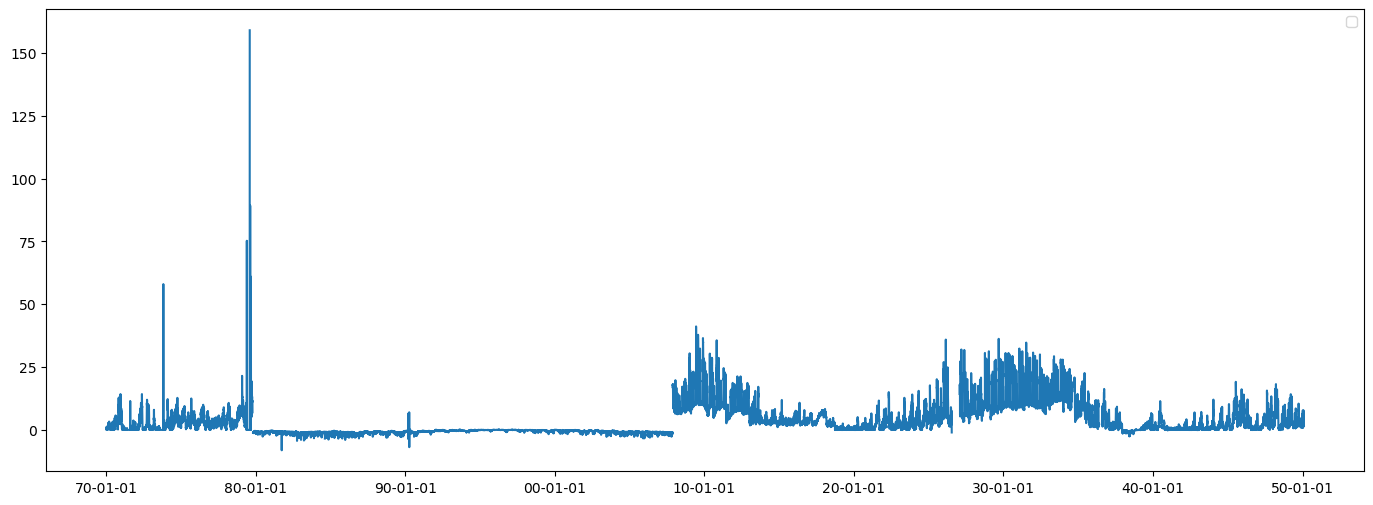

In [6]:
plt.figure(figsize=(17, 6))
plt.plot(df.index, df['b103'])

days = mdates.AutoDateLocator()
plt.gca().xaxis.set_major_locator(days)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%y-%m-%d'))

plt.legend()
plt.show()

### Neural ODE

In [ ]:
import torch
import torch.nn as nn
from torchdiffeq import odeint
import numpy as np

class NeuralODE(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)

    def forward(self, t, y):
        return self.fc2(torch.relu(self.fc1(y)))

class HybridTransformer(nn.Module):
    def __init__(self, input_dim, num_heads, num_layers=2, hidden_dim=128):
        super(HybridTransformer, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        # Transformer Encoder Layer
        encoder_layer = nn.TransformerEncoderLayer(d_model=hidden_dim, nhead=num_heads)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Fully connected layer for embedding
        self.fc_embed = nn.Linear(input_dim, hidden_dim)

        # Output layer for anomaly scores
        self.fc_out = nn.Linear(hidden_dim, 1)

    def forward(self, src):
        print("Input shape before reshape:", src.shape)

        # 입력 차원 자동 조정
        batch_size, seq_length = src.shape[0], src.shape[1]
        if src.shape[-1] != self.input_dim:  # 예상과 다르면 조정
            self.input_dim = src.shape[-1]
            self.fc_embed = nn.Linear(self.input_dim, self.hidden_dim)

        # (batch_size, seq_length, input_dim) 형태로 변환
        src = src.view(batch_size, seq_length, self.input_dim)
        print("Input shape after reshape:", src.shape)

        # Linear Embedding 적용
        src = self.fc_embed(src)  # (batch_size, seq_len, hidden_dim)
        print("Input shape after embedding:", src.shape)

        # Transformer 적용
        src = self.transformer(src)  # (batch_size, seq_len, hidden_dim)

        # 최종 예측값 도출
        output = self.fc_out(src).squeeze(-1)  # (batch_size, seq_len)

        return output
    
def detect_spikes_with_hybrid_attention(df, column_names):
    data = df[column_names].dropna()
    data_tensor = torch.tensor(data.values, dtype=torch.float32)

    num_heads = 4
    original_dim = data_tensor.shape[1]
    input_dim = ((original_dim + num_heads - 1) // num_heads) * num_heads

    if data_tensor.shape[1] < input_dim:
        padding = torch.zeros((data_tensor.shape[0], input_dim - data_tensor.shape[1]))
        data_tensor = torch.cat([data_tensor, padding], dim=1)

    neural_ode = NeuralODE(input_dim=input_dim, hidden_dim=64)
    t = torch.linspace(0, 1, data_tensor.size(0))

    solutions = []
    for i in range(data_tensor.size(0)):
        y0 = data_tensor[i].unsqueeze(0)
        sol = odeint(neural_ode, y0, t)
        solutions.append(sol[-1])  # 마지막 시점만 저장

    solution = torch.stack(solutions, dim=0).unsqueeze(0)  # (1, seq_len, input_dim)

    print("Modified solution shape:", solution.shape)

    hybrid_transformer = HybridTransformer(input_dim=input_dim, num_heads=num_heads, num_layers=2, hidden_dim=128)
    anomaly_scores = hybrid_transformer(solution)

    # 평균 + 3표준편차 방식으로 threshold 자동 설정
    mean_score = anomaly_scores.mean().item()
    std_score = anomaly_scores.std().item()
    threshold = mean_score + 3 * std_score

    spikes = (anomaly_scores.squeeze() > threshold).float()

    return spikes, anomaly_scores, threshold


spikes, anomaly_scores, threshold = detect_spikes_with_hybrid_attention(df, ['b055', 'b103', 'b166', 'b002', 'b084'])

print("Detected spikes:", spikes)
print("Threshold used:", threshold)

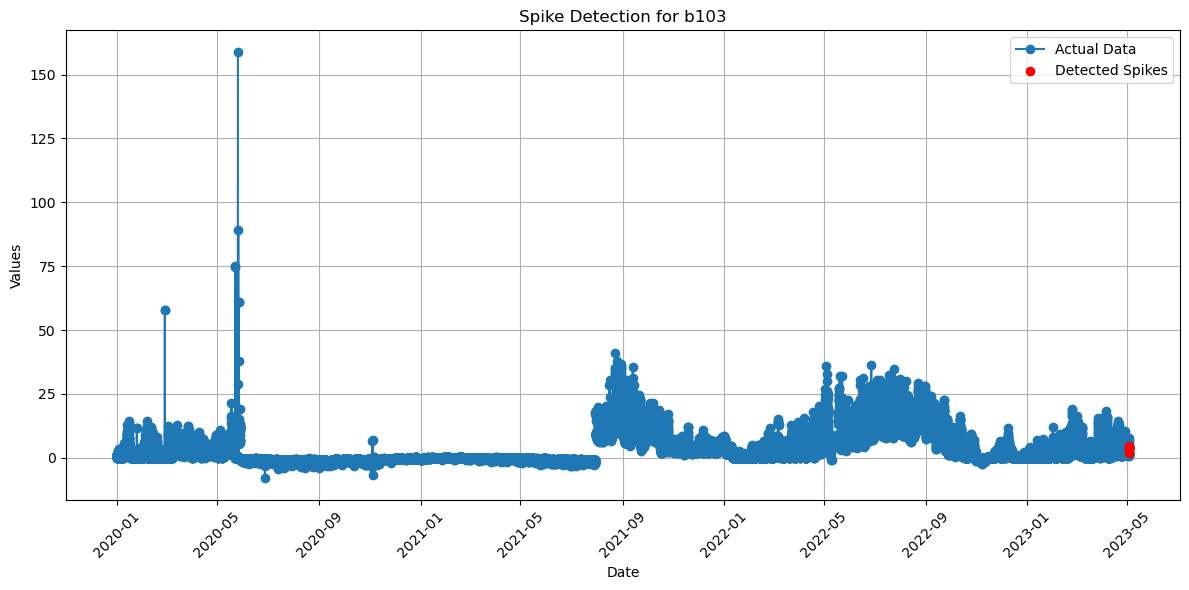

In [ ]:
def plot_spikes_for_single_variable(df, col, spikes):
    df['date'] = pd.to_datetime(df['date'])  

    plt.figure(figsize=(12, 6))
    plt.plot(df['date'], df[col], label='Actual Data', marker='o', linestyle='-')

    if isinstance(spikes, np.ndarray) is False:
        spikes = spikes.detach().cpu().numpy()

    if spikes.ndim > 1:
        spikes = spikes.squeeze()

    # Boolean 변환
    spike_indices = spikes.astype(bool)

    # 스파이크 배열 길이를 df 길이에 맞춤
    if len(spike_indices) != len(df):
        print(f"Warning: spikes length ({len(spike_indices)}) does not match df length ({len(df)}). Adjusting indices.")
        df_filtered = df.iloc[-len(spike_indices):]  # df의 마지막 부분과 일치하도록 자름
    else:
        df_filtered = df

    # 스파이크 감지된 데이터 선택
    spike_dates = df_filtered.loc[spike_indices, 'date']
    spike_values = df_filtered.loc[spike_indices, col]

    plt.scatter(spike_dates, spike_values, color='red', label='Detected Spikes', zorder=5)

    plt.title(f'Spike Detection for {col}')
    plt.xlabel('Date')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

df['date'] = pd.to_datetime(df['date'])
plot_spikes_for_single_variable(df, 'b103', spikes)


In [7]:
### ODE-RNN with Time Encoding + Causal/Time Series Transformer
import torch
import torch.nn as nn
from torchdiffeq import odeint
import numpy as np

# 1. Neural ODE 정의 (shared by Encoder and Decoder)
class NeuralODEFunc(nn.Module):
    def __init__(self, hidden_dim, depth=4, dropout=0.1):
        super(NeuralODEFunc, self).__init__()
        layers = []
        for i in range(depth):
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.LayerNorm(hidden_dim))
            layers.append(nn.Dropout(dropout))
        self.net = nn.Sequential(*layers)

    def forward(self, t, h):
        return self.net(h)

# 2. ODE-RNN Encoder (with time encoding)
class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODERNNEncoder, self).__init__()
        self.hidden_dim = hidden_dim
        self.rnn_cell = nn.GRUCell(input_dim + 1, hidden_dim)  # +1 for time encoding
        self.ode_func = NeuralODEFunc(hidden_dim)

    def forward(self, x, time_steps):
        batch_size, seq_len, _ = x.size()
        h = torch.zeros(batch_size, self.hidden_dim).to(x.device)
        h_list = []

        for i in range(seq_len):
            if i > 0:
                delta_t = (time_steps[i] - time_steps[i - 1]).unsqueeze(0).repeat(batch_size, 1)
                t = torch.tensor([0, delta_t[0, 0]]).to(x.device)
                h = odeint(self.ode_func, h, t)[-1]
            else:
                delta_t = torch.zeros((batch_size, 1)).to(x.device)

            x_i = torch.cat([x[:, i, :], delta_t], dim=1)
            h = self.rnn_cell(x_i, h)
            h_list.append(h.unsqueeze(1))

        return torch.cat(h_list, dim=1)

# 3. ODE Decoder (Latent to output sequence)
class ODEDecoder(nn.Module):
    def __init__(self, hidden_dim, output_dim):
        super(ODEDecoder, self).__init__()
        self.ode_func = NeuralODEFunc(hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, z0, predict_times):
        z = odeint(self.ode_func, z0, predict_times)
        z = z.permute(1, 0, 2)
        return self.output_layer(z)

# 4. Causal Time Series Transformer
class TimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim, num_heads, num_layers=2, hidden_dim=128):
        super(TimeSeriesTransformer, self).__init__()
        self.fc_embed = nn.Linear(input_dim, hidden_dim)
        encoder_layer = nn.TransformerEncoderLayer(d_model=hidden_dim, nhead=num_heads, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(hidden_dim, 1)

    def forward(self, src):
        src = self.fc_embed(src)
        src = self.transformer(src)
        return self.fc_out(src).squeeze(-1)

# 5. 통합 모델
class SpikeDetector(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_heads=4):
        super(SpikeDetector, self).__init__()
        self.encoder = ODERNNEncoder(input_dim=input_dim, hidden_dim=hidden_dim)
        self.decoder = ODEDecoder(hidden_dim=hidden_dim, output_dim=input_dim)
        self.transformer = TimeSeriesTransformer(input_dim=input_dim, num_heads=num_heads)

    def forward(self, x, time_steps):
        h_encoded = self.encoder(x, time_steps)
        z0 = h_encoded[:, -1, :]
        predicted = self.decoder(z0, time_steps)
        anomaly_scores = self.transformer(predicted)
        return anomaly_scores

# 6. Inference Function

def detect_spikes_with_ode_rnn(df, column_names):
    data = df[column_names].dropna()
    data_tensor = torch.tensor(data.values, dtype=torch.float32)
    time_steps = torch.linspace(0, 1, data_tensor.shape[0])

    num_heads = 4
    original_dim = data_tensor.shape[1]
    input_dim = ((original_dim + num_heads - 1) // num_heads) * num_heads
    if original_dim < input_dim:
        padding = torch.zeros((data_tensor.shape[0], input_dim - original_dim))
        data_tensor = torch.cat([data_tensor, padding], dim=1)

    x = data_tensor.unsqueeze(0)
    time_steps = time_steps.to(data_tensor.device)

    model = SpikeDetector(input_dim=input_dim, hidden_dim=128, num_heads=num_heads)
    anomaly_scores = model(x, time_steps)

    mean_score = anomaly_scores.mean().item()
    std_score = anomaly_scores.std().item()
    threshold = mean_score + 3 * std_score

    spikes = (anomaly_scores.squeeze() > threshold).float()

    return spikes, anomaly_scores, threshold

# 호출 예시
spikes, anomaly_scores, threshold = detect_spikes_with_ode_rnn(df, ['b055', 'b103', 'b166', 'b002', 'b084'])

print("Detected spikes:", spikes)
print("Threshold used:", threshold)


KeyboardInterrupt: 

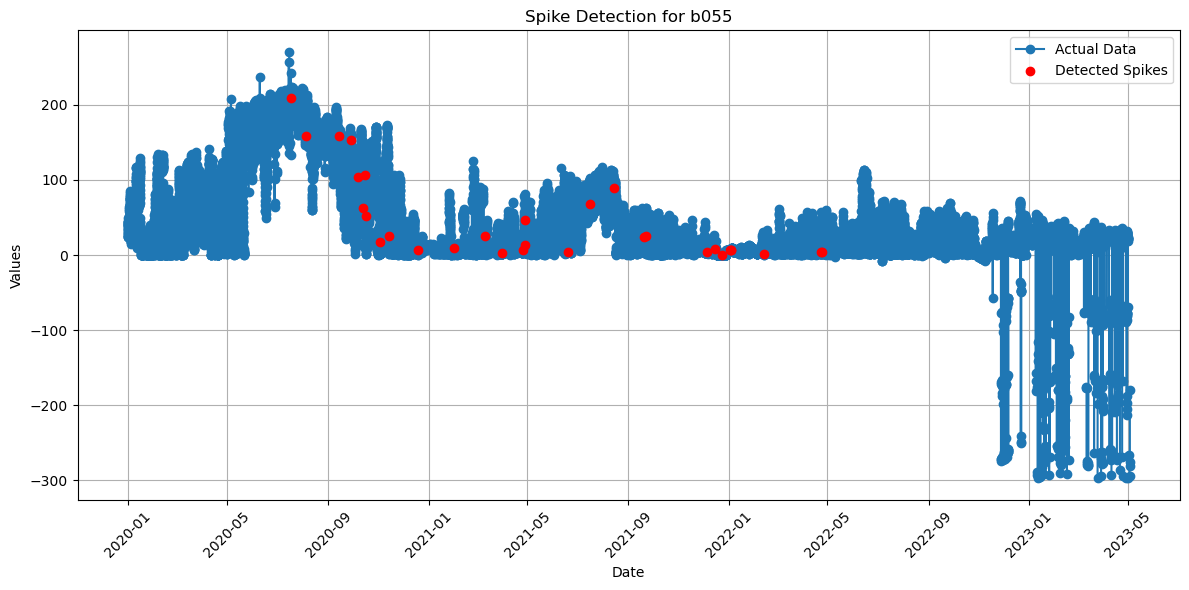

In [11]:
def plot_spikes_for_single_variable(df, col, spikes):
    df['date'] = pd.to_datetime(df['date'])  

    plt.figure(figsize=(12, 6))
    plt.plot(df['date'], df[col], label='Actual Data', marker='o', linestyle='-')

    if isinstance(spikes, np.ndarray) is False:
        spikes = spikes.detach().cpu().numpy()

    if spikes.ndim > 1:
        spikes = spikes.squeeze()

    # Boolean 변환
    spike_indices = spikes.astype(bool)

    # 스파이크 배열 길이를 df 길이에 맞춤
    if len(spike_indices) != len(df):
        print(f"Warning: spikes length ({len(spike_indices)}) does not match df length ({len(df)}). Adjusting indices.")
        df_filtered = df.iloc[-len(spike_indices):]  # df의 마지막 부분과 일치하도록 자름
    else:
        df_filtered = df

    # 스파이크 감지된 데이터 선택
    spike_dates = df_filtered.loc[spike_indices, 'date']
    spike_values = df_filtered.loc[spike_indices, col]

    plt.scatter(spike_dates, spike_values, color='red', label='Detected Spikes', zorder=5)

    plt.title(f'Spike Detection for {col}')
    plt.xlabel('Date')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

df['date'] = pd.to_datetime(df['date'])
plot_spikes_for_single_variable(df, 'b055', spikes)

In [120]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# Sinusoidal Time Embedding
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super(SinusoidalTimeEmbedding, self).__init__()
        # Automatically make the embedding_dim even if it's odd
        if embedding_dim % 2 != 0:
            embedding_dim += 1  # Add 1 to make it even
        self.embedding_dim = embedding_dim

    def forward(self, time_steps):
        device = time_steps.device
        batch_size, seq_len = time_steps.size()
        pe = torch.zeros(batch_size, seq_len, self.embedding_dim).to(device)

        position = time_steps.unsqueeze(-1)  # [batch_size, seq_len, 1]
        div_term = torch.exp(torch.arange(0, self.embedding_dim, 2, dtype=torch.float32).to(device) *
                             -(np.log(10000.0) / self.embedding_dim))  # [embedding_dim // 2]
        
        # Ensure the shape alignment for both sin and cos computations
        pe[..., 0::2] = torch.sin(position * div_term)  # Sine part
        pe[..., 1::2] = torch.cos(position * div_term)  # Cosine part

        return pe

# ODE Function
class ODEF(nn.Module):
    def __init__(self, hidden_dim):
        super(ODEF, self).__init__()
        self.linear1 = nn.Linear(hidden_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, t, h):
        return self.linear2(self.relu(self.linear1(h)))

# GRU-style ODE-RNN Encoder
class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODERNNEncoder, self).__init__()
        self.hidden_dim = hidden_dim
        self.odefunc = ODEF(hidden_dim)
        self.gru = nn.GRUCell(input_dim, hidden_dim)
        self.h0 = nn.Parameter(torch.zeros(hidden_dim))

    def forward(self, x, time_steps):
        batch_size, seq_len, _ = x.size()
        h = self.h0.unsqueeze(0).repeat(batch_size, 1)

        outputs = []
        for i in range(seq_len):
            if i > 0:
                dt = time_steps[:, i] - time_steps[:, i - 1]
                h = h + self.odefunc(None, h) * dt.unsqueeze(1)
            h = self.gru(x[:, i], h)
            outputs.append(h.unsqueeze(1))

        return torch.cat(outputs, dim=1)

# ODE-based Decoder
class ODEDecoder(nn.Module):
    def __init__(self, hidden_dim, output_dim):
        super(ODEDecoder, self).__init__()
        self.odefunc = ODEF(hidden_dim)
        self.linear = nn.Linear(hidden_dim, output_dim)

    def forward(self, z0, time_steps):
        batch_size, seq_len = time_steps.size()
        h = z0
        outputs = []
        for i in range(seq_len):
            if i > 0:
                # Ensure time_steps are correctly reshaped for element-wise operations
                dt = time_steps[:, i] - time_steps[:, i - 1]
                dt = dt.unsqueeze(1)  # This ensures dt has the shape [batch_size, 1]
                h = h + self.odefunc(None, h) * dt  # Ensure the dimensions of h and dt align

            outputs.append(self.linear(h).unsqueeze(1))
        return torch.cat(outputs, dim=1)


# Transformer with Causal Masking
class TimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim, num_heads, num_layers=2, hidden_dim=128):
        super(TimeSeriesTransformer, self).__init__()
        self.fc_embed = nn.Linear(input_dim, hidden_dim)
        encoder_layer = nn.TransformerEncoderLayer(d_model=hidden_dim, nhead=num_heads, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(hidden_dim, 1)  

    def generate_causal_mask(self, size):
        # (seq_len, seq_len)
        return torch.triu(torch.ones(size, size), diagonal=1).bool()

    def forward(self, src):
        batch_size, seq_len, _ = src.size()
        src = self.fc_embed(src)
        mask = self.generate_causal_mask(seq_len).to(src.device)
        out = self.transformer(src, mask=mask)
        return self.fc_out(out).squeeze(-1)  

class SpikeDetectorBinaryClassification(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_heads=4):
        super(SpikeDetectorBinaryClassification, self).__init__()
        self.encoder = ODERNNEncoder(input_dim=input_dim, hidden_dim=hidden_dim)
        self.decoder = ODEDecoder(hidden_dim=hidden_dim, output_dim=input_dim)
        self.time_embedding = SinusoidalTimeEmbedding(embedding_dim=input_dim)
        self.transformer = TimeSeriesTransformer(input_dim=input_dim, num_heads=num_heads)

    def forward(self, x, time_steps):
        # Forward pass through encoder, passing both x and time_steps
        encoded = self.encoder(x, time_steps)  # shape: [batch_size, seq_len, hidden_dim]
        
        # 디코더는 배치 차원의 벡터를 기대하므로 마지막 time step의 값을 사용
        z0 = encoded[:, -1, :]  # shape: [batch_size, hidden_dim]
        
        # Forward pass through the decoder
        predicted = self.decoder(z0, time_steps)  # shape: [batch_size, seq_len, input_dim]
        
        # Apply time embedding
        time_embed = self.time_embedding(time_steps)  # shape: [batch_size, seq_len, input_dim]
        
        # 차원 맞추기 - time_embed를 predicted 크기에 맞춤
        if time_embed.size(2) != predicted.size(2):
            # time_embed 차원 조정
            time_embed = time_embed[:, :, :predicted.size(2)]
        
        # predicted와 time_embed 결합
        predicted_with_time = predicted + time_embed
        
        # Continue with the rest of the forward pass
        anomaly_scores = self.transformer(predicted_with_time)
        
        # 출력에 시그모이드 함수 적용하여 0~1 사이 값으로 변환
        return torch.sigmoid(anomaly_scores)
    
# 예시 입력
# batch_size = 512
#seq_len = 256
#input_dim = 128

#x = torch.randn(batch_size, seq_len, input_dim)
# time_steps = torch.sort(torch.rand(batch_size, seq_len), dim=1)[0]  # 오름차순 시간

# model = SpikeDetectorBinaryClassification(input_dim=input_dim)
# output = model(x, time_steps)  # output shape: [batch_size, seq_len, 1] 확률값

# 이진 분류 확률을 0.5 기준으로 예측
# predictions = (output > 0.5).float()

In [ ]:
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim

# Dataset transform
train_dataset = TensorDataset(torch.tensor(x_trn, dtype=torch.float32),
                              torch.tensor(np.arange(x_trn.shape[0])[:, None].repeat(x_trn.shape[1], axis=1), dtype=torch.float32))  

test_dataset = TensorDataset(torch.tensor(x_tst, dtype=torch.float32),
                             torch.tensor(np.arange(x_tst.shape[0])[:, None].repeat(x_tst.shape[1], axis=1), dtype=torch.float32),
                             torch.tensor(lab_tst, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128)

model = SpikeDetectorBinaryClassification(input_dim=x_trn.shape[2])
optimizer = optim.Adam(model.parameters(), lr=1e-3)

reconstruction_errors = []

for epoch in range(50):
    model.train()
    total_loss = 0
    for x_batch, time_steps in train_loader:
        x_batch = x_batch
        time_steps = time_steps.squeeze()

        optimizer.zero_grad()
        outputs = model(x_batch, time_steps)  
        labels = torch.zeros_like(outputs) 
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} - Train Loss: {total_loss:.4f}")

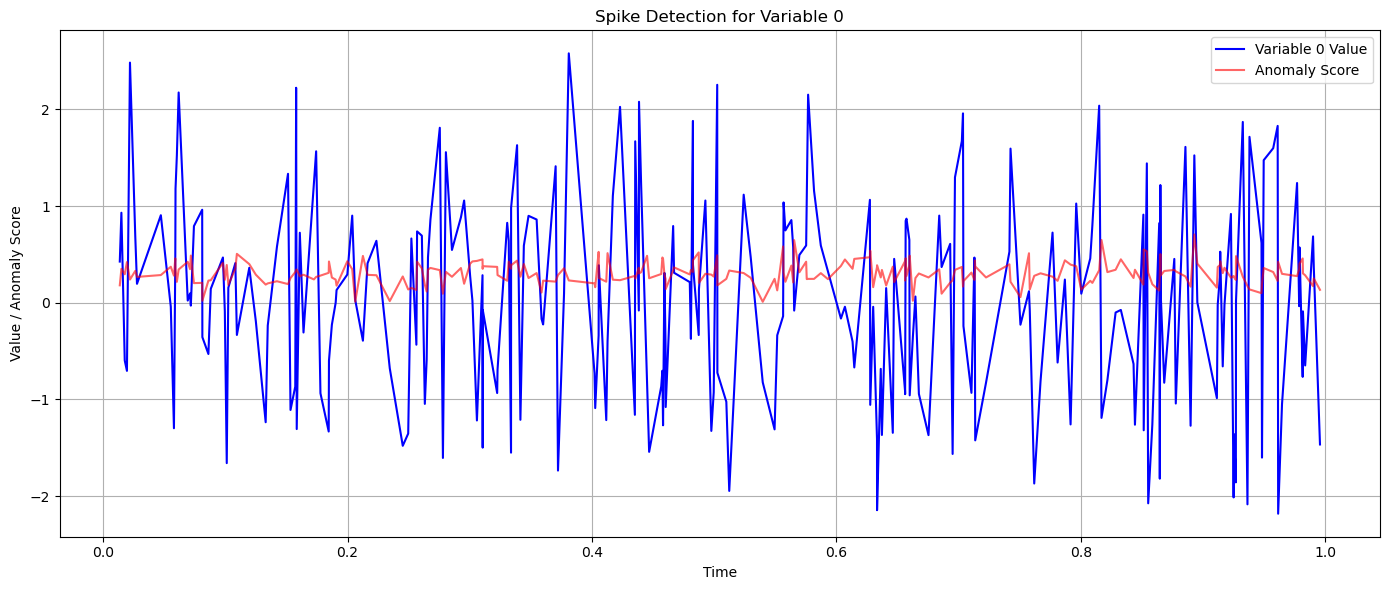

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# 예시 변수 인덱스 (0부터 127 사이)
var_idx = 0

# 해당 변수의 실제 값 (shape: [batch_size, seq_len])
x_var = x[:, :, var_idx].detach().cpu().numpy()

# spike 점수 (shape: [batch_size, seq_len])
spike_scores = output.detach().cpu().numpy()

# 시간 (shape: [batch_size, seq_len])
time_vals = time_steps.detach().cpu().numpy()

# 하나의 sample만 선택해서 시각화 (예: 첫 번째 배치)
sample_idx = 0
x_sample = x_var[sample_idx]
score_sample = spike_scores[sample_idx]
time_sample = time_vals[sample_idx]

# Plot
plt.figure(figsize=(14, 6))
plt.plot(time_sample, x_sample, label=f'Variable {var_idx} Value', color='blue')
plt.plot(time_sample, score_sample, label='Anomaly Score', color='red', alpha=0.6)
plt.title(f'Spike Detection for Variable {var_idx}')
plt.xlabel('Time')
plt.ylabel('Value / Anomaly Score')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:
import matplotlib.pyplot as plt
import numpy as np

def plot_spike_detection_for_variable(x, time_steps, anomaly_scores, var_idx=0, threshold=None, sample_idx=0, percentile=95):
    """
    x: (batch, seq_len, input_dim) - 입력 시계열
    time_steps: (batch, seq_len) - 시간 정보
    anomaly_scores: (batch, seq_len) - 모델 출력 anomaly score
    var_idx: int - 시각화할 변수 인덱스 (ex. 0~127)
    sample_idx: int - 배치 중 어떤 시계열을 볼지 (기본값: 0)
    threshold: float - anomaly 판단 기준값. 없으면 percentile 기반 계산
    percentile: float - threshold를 anomaly_scores의 상위 몇 %로 지정할지
    """

    # Tensor → NumPy
    x_np = x.detach().cpu().numpy()
    time_np = time_steps.detach().cpu().numpy()
    score_np = anomaly_scores.detach().cpu().numpy()

    # 하나의 시계열 추출
    values = x_np[sample_idx, :, var_idx]
    times = time_np[sample_idx]
    scores = score_np[sample_idx]

    # threshold 계산 (percentile 기반 or 수동 입력)
    if threshold is None:
        threshold = np.percentile(scores, percentile)
    
    # spike 위치
    spikes = scores > threshold

    # 시각화
    fig, ax1 = plt.subplots(figsize=(14, 5))

    # 실제 값 plot
    ax1.set_title(f"Spike Detection for Variable {var_idx}")
    ax1.plot(times, values, label=f'Variable {var_idx} Value', color='blue', marker='o')
    ax1.set_xlabel("Time")
    ax1.set_ylabel("Variable Value", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    # spike 점 찍기
    ax1.scatter(times[spikes], values[spikes], color='red', label='Detected Spikes', zorder=5)

    # anomaly score plot (우측 축)
    ax2 = ax1.twinx()
    ax2.plot(times, scores, color='orange', linestyle='--', label='Anomaly Score')
    ax2.axhline(threshold, color='gray', linestyle=':', label='Threshold')
    ax2.set_ylabel("Anomaly Score", color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')

    # 범례 정리
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 간단 출력
    print("Total spikes detected:", spikes.sum())
    print("Threshold used:", threshold)


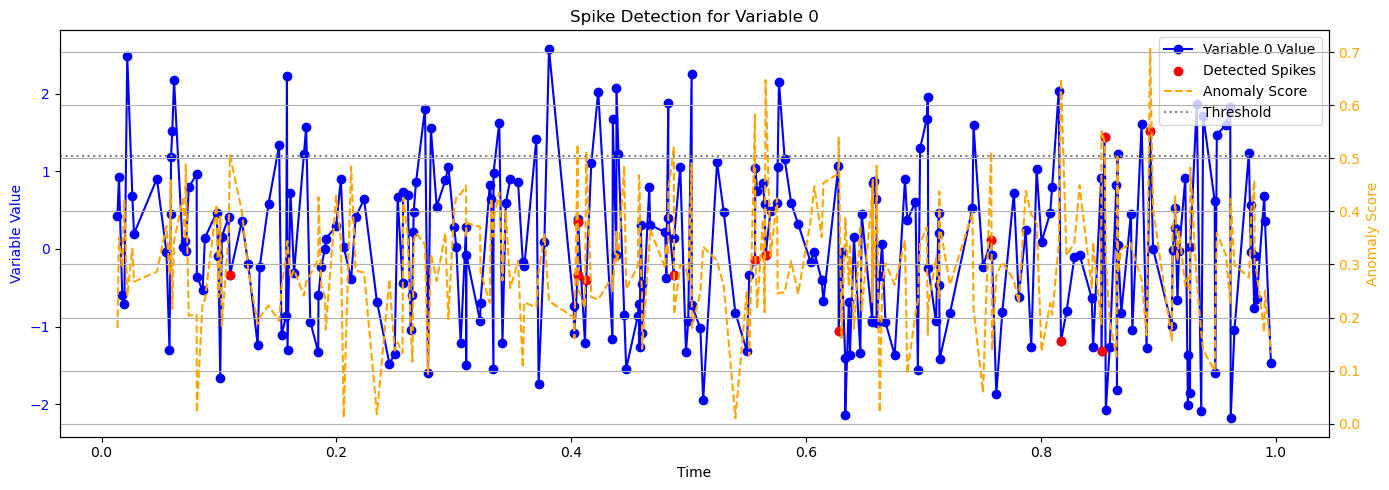

Total spikes detected: 13
Threshold used: 0.5039343386888504


In [11]:
plot_spike_detection_for_variable(x, time_steps, output, var_idx=0, percentile=95)

In [7]:
import matplotlib.pyplot as plt
import numpy as np

def plot_spike_detection_from_df(df, variable_name, anomaly_scores, start_idx, threshold=None, percentile=95):
    """
    df: 전체 DataFrame
    variable_name: 예측할 변수명
    anomaly_scores: 모델 출력값 (Tensor or ndarray), 길이는 시퀀스 길이 (예: 256)
    start_idx: anomaly_scores가 적용된 df 시작 index
    """

    # 필요한 값 추출
    times = pd.to_datetime(df['date'].values)
    values = df[variable_name].values

    # scores 처리
    if isinstance(anomaly_scores, torch.Tensor):
        scores = anomaly_scores.detach().cpu().numpy()
    else:
        scores = anomaly_scores

    # threshold 계산
    if threshold is None:
        threshold = np.percentile(scores, percentile)

    spikes = scores > threshold

    # 스파이크 대응할 위치만 자르기
    ts = times[start_idx:start_idx+len(scores)]
    vs = values[start_idx:start_idx+len(scores)]

    # 시각화
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax1.set_title(f"Spike Detection on '{variable_name}'")

    ax1.plot(ts, vs, label=f'{variable_name}', color='blue', marker='o')
    ax1.scatter(ts[spikes], vs[spikes], color='red', label='Detected Spikes', zorder=5)
    ax1.set_ylabel("Value", color='blue')
    ax1.set_xlabel("Date")
    ax1.tick_params(axis='y', labelcolor='blue')

    # 오른쪽 축: anomaly score
    ax2 = ax1.twinx()
    ax2.plot(ts, scores, label='Anomaly Score', color='orange', linestyle='--')
    ax2.axhline(threshold, color='gray', linestyle=':', label='Threshold')
    ax2.set_ylabel("Anomaly Score", color='orange')
    ax2.tick_params(axis='y', labelcolor='orange')

    # 범례
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("Total spikes detected:", int(spikes.sum()))
    print("Max anomaly score:", scores.max())
    print("Threshold used:", threshold)


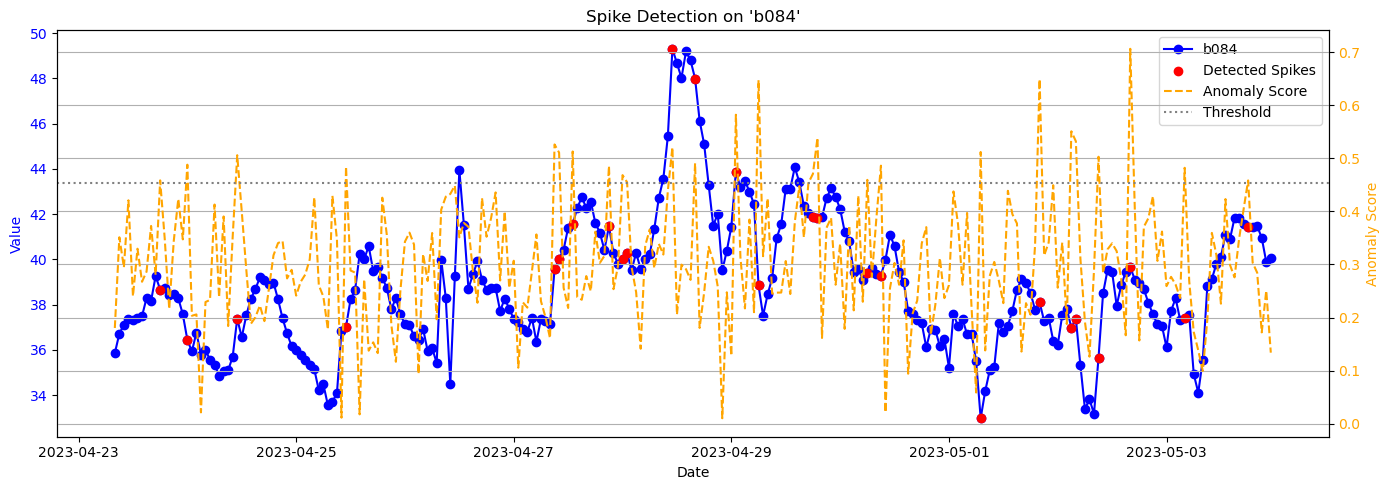

Total spikes detected: 26
Max anomaly score: 0.7067979
Threshold used: 0.45454564690589905


In [13]:
# 예: 마지막 256개 구간에 대해 anomaly score 예측
start_index = len(df) - 256

plot_spike_detection_from_df(df, 'b084', anomaly_scores=output[0], start_idx=start_index, percentile=90)


### Open dataset

In [68]:
### SMD 
import kagglehub
import shutil
import os

# Download latest version
path = kagglehub.dataset_download("mgusat/smd-onmiad")

print("Path to dataset files:", path)

# 현재 경로 (KaggleHub 캐시)
source_path = "/Users/jieun/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1"
# 원하는 경로 (예: ./data/SMD)
destination_path = "./datasets/SMD"

os.makedirs(destination_path, exist_ok=True)

for item in os.listdir(source_path):
    s = os.path.join(source_path, item)
    d = os.path.join(destination_path, item)
    if os.path.isdir(s):
        shutil.copytree(s, d, dirs_exist_ok=True)
    else:
        shutil.copy2(s, d)

print("✅ SMD 데이터 복사 완료:", destination_path)

Path to dataset files: /Users/jieun/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1
✅ SMD 데이터 복사 완료: ./datasets/SMD


In [69]:
import os
import pickle as pk

import numpy as np
import pandas as pd

pth = './datasets/SMD/ServerMachineDataset/'

x_trn, x_tst, lab_tst = [], [], []
for ent_name in os.listdir(pth + 'train'):
    x_trn.append(pd.read_csv(pth + 'train/' + ent_name, header=None).to_numpy())
    x_tst.append(pd.read_csv(pth + 'test/' + ent_name, header=None).to_numpy())
    lab_tst.append(np.squeeze(pd.read_csv(pth + 'test_label/' + ent_name, header=None).to_numpy()))
    
print('Dumping pickle files...')
with open(pth + 'SMD.pk', 'wb') as file:
    pk.dump({'x_trn': x_trn, 'x_tst': x_tst, 'lab_tst': lab_tst}, file)


Dumping pickle files...


In [70]:
class Params:
    def __init__(self, dl, stride, tst_stride, train_method='train_all_entities', clamp_max=None, clamp_min=None, entity_id=None, downsample=None):
        self.dl = dl
        self.stride = stride
        self.tst_stride = tst_stride
        self.train_method = train_method
        self.clamp_max = clamp_max
        self.clamp_min = clamp_min
        self.entity_id = entity_id
        self.downsample = downsample

In [81]:
from datasets.SMD.preprocess_SMD import SMD_Dataset  

# 설정
dataset_path = './datasets/SMD/ServerMachineDataset/SMD.pk'
params = Params(
    dl=64,
    stride=16,
    tst_stride='no_rep',
    train_method='train_per_entity',  # 또는 'train_per_entity'
    entity_id=1  # 'train_per_entity' 방식일 때만 사용
)

# 데이터셋 객체 생성 및 전처리
smd_data = SMD_Dataset(dataset_path, entities='all')
smd_data = smd_data.preprocess(params)

x_trn = smd_data['x_trn']
x_tst = smd_data['x_tst']
lab_tst = smd_data['lab_tst']

print("x_trn shape:", x_trn.shape)
print("x_tst shape:", x_tst.shape)
print("lab_tst shape:", lab_tst.shape)

using entity 1/27
Original shapes x_trn, x_tst, lab_tst= (28695, 38) (28696, 38) (28696,)
Deleted channels with std = 0 x_trn, x_tst= (28695, 31) (28696, 31)
Applied minmax normalization
AR = 0.0069 (198 / 28696)
Rounded x_trn, x_tst, lab_tst= (28688, 31) (28672, 31) (28672,)
Add two additional channels (38 sens + 2 add = 40 = 8 heads * 5)
Window/strided x_trn [=] (1790, 64, 33); x_tst [=] (448, 64, 33); lab_tst [=] (448, 64)
x_trn shape: (1790, 64, 33)
x_tst shape: (448, 64, 33)
lab_tst shape: (448, 64)


In [106]:
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim

# Dataset transform
train_dataset = TensorDataset(torch.tensor(x_trn, dtype=torch.float32),
                              torch.tensor(np.arange(x_trn.shape[0])[:, None].repeat(x_trn.shape[1], axis=1), dtype=torch.float32))  

test_dataset = TensorDataset(torch.tensor(x_tst, dtype=torch.float32),
                             torch.tensor(np.arange(x_tst.shape[0])[:, None].repeat(x_tst.shape[1], axis=1), dtype=torch.float32),
                             torch.tensor(lab_tst, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128)

model = SpikeDetectorBinaryClassification(input_dim=x_trn.shape[2])
optimizer = optim.Adam(model.parameters(), lr=1e-3)

reconstruction_errors = []

for epoch in range(50):
    model.train()
    total_loss = 0
    for x_batch, time_steps in train_loader:
        x_batch = x_batch
        time_steps = time_steps

        optimizer.zero_grad()
        outputs = model(x_batch, time_steps)  
        labels = torch.zeros_like(outputs) 
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} - Train Loss: {total_loss:.4f}")


TypeError: ODERNNEncoder.forward() missing 1 required positional argument: 'time_steps'

In [94]:
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for x_batch, time_steps, labels in test_loader:
        x_batch = x_batch
        time_steps = time_steps
        outputs = model(x_batch, time_steps) 
        preds = (outputs > 0.5).float().cpu().numpy()
        all_preds.append(preds)
        all_labels.append(labels.numpy())

y_pred = np.concatenate(all_preds).flatten()
y_true = np.concatenate(all_labels).flatten()

precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary')
auc = roc_auc_score(y_true, y_pred)

print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, AUC: {auc:.4f}")

Precision: 0.0000, Recall: 0.0000, F1: 0.0000, AUC: 0.4742


In [24]:
### trimSyn
import os
import numpy as np
import pandas as pd
import pickle as pk
import matplotlib.pyplot as plt

# https://epubs.siam.org/doi/abs/10.1137/1.9781611977653.ch77
# https://sites.google.com/view/tsadis
datapath = './data/MSCRED/MSCRED.csv'

dat = pd.read_csv(datapath, index_col=0)
dat_gt = pd.read_csv('./data/MSCRED/MSCRED_GT.csv', index_col=0)

# dataset split according to https://arxiv.org/abs/1811.08055
trn_tst_split_point = 10000

x_trn = dat[:trn_tst_split_point].values
x_tst_cont = dat[trn_tst_split_point:].values
lab_tst_cont = (dat_gt[trn_tst_split_point:].values.sum(axis=1) > 0) * 1
x_tst = []
lab_tst = []

# # extract test sections
tst_sections = [[0, 1720], [1900, 2850], [4630, 7700], [7880, 8530], [8710, 10000]]
errors = 0
num_points = 0
for sec in tst_sections:
    errors += lab_tst_cont[sec[0]:sec[1]].sum()
    num_points += sec[1] - sec[0]
    x_tst.append(x_tst_cont[sec[0]:sec[1]])
    lab_tst.append(lab_tst_cont[sec[0]:sec[1]])
anomaly_rate = errors / num_points
print('anomaly rate =', anomaly_rate)
x_trn = [x_trn] * len(tst_sections)

# save dataset to pickle file
trimSyn_path = './data/MSCRED/trimSyn.pk'
with open(trimSyn_path, 'wb') as pkf:
    pk.dump({'x_trn': x_trn, 'x_tst': x_tst, 'lab_tst': lab_tst}, pkf)

anomaly rate = 0.0234375


In [64]:
import os
import numpy as np
import torch
import pickle as pk

# this should be available
import utils.preprocess as prep

# trimSyn dataset
class trimSyn_Dataset():
    def __init__(self, dataset_pth, entities):
        self.dims = 30
        with open(dataset_pth, 'rb') as file:
            self.dat = pk.load(file)
        if entities != 'all':
            self.dat['x_trn'] = [self.dat['x_trn'][entity] for entity in entities]
            self.dat['x_tst'] = [self.dat['x_tst'][entity] for entity in entities]
            self.dat['lab_tst'] = [self.dat['lab_tst'][entity] for entity in entities]
            self.num_entity = len(entities)
        else:
            self.num_entity = 5

    def preprocess(self, params):
    
        dl = params['dl']
        stride = params['stride']
        tst_stride = dl if params['tst_stride'] == 'no_rep' else params['tst_stride']

        if params['train_method'] == 'train_per_entity':
            if params['entity_id'] == self.num_entity:
                return None
            print(f"using entity {params['entity_id']}/{self.num_entity - 1}")
            dat = {}
            dat['x_trn'] = self.dat['x_trn'][params['entity_id']]
            dat['x_tst'] = self.dat['x_tst'][params['entity_id']]
            dat['lab_tst'] = self.dat['lab_tst'][params['entity_id']]
            self.num_entity = 1
            dat = prep.preprocess(dat, params, self.dims, self.num_entity, None)
            return prep.window_stride(dat['x_trn'], dat['x_tst'], dat['lab_tst'], self.num_entity, dl, stride, tst_stride)
        else:
            # preprocess self.dat by each entity!
            x_trn_all, x_tst_all, lab_tst_all = [], [], []
            for entity_id in range(self.num_entity):
                dat_ent = {}
                for key in self.dat.keys():
                    dat_ent[key] = self.dat[key][entity_id]
                dat = prep.preprocess(dat_ent, params, self.dims, self.num_entity, entity_id, quiet=True)
                x_trn_all.append(dat['x_trn'])
                x_tst_all.append(dat['x_tst'])
                lab_tst_all.append(dat['lab_tst'])

            return prep.window_stride(x_trn_all, x_tst_all, lab_tst_all, self.num_entity, dl, stride, tst_stride)

In [65]:
# 데이터셋 로드
dataset_pth = './data/MSCRED/trimSyn.pk'  # 데이터셋 경로
entities = 'all'  # 사용할 엔티티 (전체 사용하려면 'all'로 설정)

# 데이터셋 객체 생성
dataset = trimSyn_Dataset(dataset_pth, entities)

# 전처리 파라미터 설정
params = {
    'dl': 32,  # 배치 크기 (예시 값)
    'stride': 5,  # 스트라이드 (예시 값)
    'tst_stride': 'no_rep',  # 테스트 스트라이드 설정 (예시 값)
    'train_method': 'train_all_entities',  # 훈련 방법 설정 (전체 엔티티 사용)
    # 'entity_id': 0,  # 'train_all_entities' 방식에서는 entity_id 필요 없음
}
# 데이터 전처리
processed_data = dataset.preprocess(params)

# processed_data는 'x_trn', 'x_tst', 'lab_tst'로 나누어져 반환됨
x_trn, x_tst, lab_tst = processed_data


TypeError: vars() argument must have __dict__ attribute

In [22]:
from torch.utils.data import DataLoader, TensorDataset

# 파라미터 클래스 정의
class Params:
    def __init__(self, dl, stride, tst_stride, train_method='train_all_entities', clamp_max=None, clamp_min=None, entity_id=None, downsample=None):
        self.dl = dl
        self.stride = stride
        self.tst_stride = tst_stride
        self.train_method = train_method
        self.clamp_max = clamp_max
        self.clamp_min = clamp_min
        self.entity_id = entity_id
        self.downsample = downsample

# 파라미터 설정
params = Params(
    dl=128,
    stride=5,
    tst_stride='no_rep',
    train_method='train_all_entities',
    clamp_max=1.0,
    clamp_min=-1.0
)

# 데이터셋 경로 및 로드
dataset_path = './data/MSCRED/trimSyn.pk'
dataset = trimSyn_Dataset(dataset_path, entities='all')

data_dict = dataset.preprocess(params)

# 필요한 데이터 추출
x_trn_all = data_dict['x_trn']
x_tst_all = data_dict['x_tst']
lab_tst_all = data_dict['lab_tst']

seq_len = x_trn_all.shape[1]  # x_trn의 시퀀스 길이
if x_tst_all.shape[1] != seq_len:
    # x_tst 길이를 x_trn과 동일하게 자르기
    x_tst_all = x_tst_all[:, :seq_len]
    lab_tst_all = lab_tst_all[:, :seq_len]

# 클램핑 처리
if params.clamp_max is not None:
    x_trn_all = torch.clamp(torch.tensor(x_trn_all, dtype=torch.float32), max=params.clamp_max)
    x_tst_all = torch.clamp(torch.tensor(x_tst_all, dtype=torch.float32), max=params.clamp_max)

if params.clamp_min is not None:
    x_trn_all = torch.clamp(x_trn_all, min=params.clamp_min)
    x_tst_all = torch.clamp(x_tst_all, min=params.clamp_min)

# 텐서로 변환
x_trn = torch.tensor(x_trn_all, dtype=torch.float32)
x_tst = torch.tensor(x_tst_all, dtype=torch.float32)
lab_tst = torch.tensor(lab_tst_all, dtype=torch.float32)

# DataLoader 설정
train_dataset = TensorDataset(x_trn, lab_tst)  # x_trn, lab_tst를 쌍으로
train_loader = DataLoader(train_dataset, batch_size=params.dl, shuffle=True)

print("x_trn:", x_trn.shape, "x_tst:", x_tst.shape, "lab_tst:", lab_tst.shape)

# 데이터 확인
for batch_idx, (x_batch, lab_batch) in enumerate(train_loader):
    print(f"Batch {batch_idx+1}, x_batch.shape: {x_batch.shape}, lab_batch.shape: {lab_batch.shape}")
    break  # 첫 번째 배치만 확인


Deleted channels with std = 0 x_trn, x_tst= (10000, 30) (1720, 30)
Deleted channels with std = 0 x_trn, x_tst= (10000, 30) (950, 30)
Deleted channels with std = 0 x_trn, x_tst= (10000, 30) (3070, 30)
Deleted channels with std = 0 x_trn, x_tst= (10000, 30) (650, 30)
Deleted channels with std = 0 x_trn, x_tst= (10000, 30) (1290, 30)
Window/strided x_trn [=] (9875, 128, 30); x_tst [=] (58, 128, 30); lab_tst [=] (58, 128)


/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_78320/27888821.py:52: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_trn = torch.tensor(x_trn_all, dtype=torch.float32)
/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_78320/27888821.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_tst = torch.tensor(x_tst_all, dtype=torch.float32)


AssertionError: Size mismatch between tensors

In [32]:
import torch
import torch.nn.functional as F
import torch.optim as optim
import pickle as pk
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn

# 디바이스 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 모델 정의 (SpikeDetectorBinaryClassification 모델 정의)
model = SpikeDetectorBinaryClassification(input_dim=128, hidden_dim=128, num_heads=4).to(device)

# 옵티마이저 및 손실 함수
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()  # 이진 분류 손실 함수

# 데이터 로딩
with open('./data/MSCRED/trimSyn.pk', 'rb') as pkf:
    data_dict = pk.load(pkf)

x_trn_all = data_dict['x_trn']
x_tst_all = data_dict['x_tst']
lab_tst_all = data_dict['lab_tst']

# 데이터셋 생성 및 DataLoader 준비
x_trn_all = torch.tensor(x_trn_all, dtype=torch.float32).to(device)
lab_tst_all = torch.tensor(lab_tst_all, dtype=torch.float32).to(device)

train_data = TensorDataset(x_trn_all, lab_tst_all)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

# 훈련 루프
epochs = 10
for epoch in range(epochs):
    model.train()  # 모델을 훈련 모드로 설정
    running_loss = 0.0
    correct_preds = 0
    total_preds = 0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)  # 배치 데이터 디바이스로 이동
        y_batch = y_batch.to(device)  # 레이블 디바이스로 이동

        # 시간 임베딩 생성
        time_steps = torch.arange(0, x_batch.size(1)).unsqueeze(0).repeat(x_batch.size(0), 1).float().to(device)

        optimizer.zero_grad()

        # 모델에 입력
        output = model(x_batch, time_steps)

        # 손실 계산
        loss = criterion(output.squeeze(), y_batch)
        loss.backward()
        optimizer.step()

        # 정확도 계산
        preds = (torch.sigmoid(output.squeeze()) > 0.5).float()
        correct_preds += (preds == y_batch).sum().item()
        total_preds += y_batch.size(0)

        running_loss += loss.item()

    # 에폭 종료 후 로그 출력
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = correct_preds / total_preds
    print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}")

# 테스트
model.eval()  # 모델을 평가 모드로 설정
with torch.no_grad():
    x_tst_tensor = torch.tensor(x_tst_all, dtype=torch.float32).to(device)
    lab_tst_tensor = torch.tensor(lab_tst_all, dtype=torch.float32).to(device)
    time_steps = torch.arange(0, x_tst_tensor.size(1)).unsqueeze(0).repeat(x_tst_tensor.size(0), 1).float().to(device)

    output = model(x_tst_tensor, time_steps)
    preds = (torch.sigmoid(output.squeeze()) > 0.5).float()

    # 평가 지표 출력
    accuracy = (preds == lab_tst_tensor).sum().item() / lab_tst_tensor.size(0)
    print(f"Test Accuracy: {accuracy:.4f}")


ValueError: expected sequence of length 1720 at dim 1 (got 950)

In [21]:
import torch
import torch.nn.functional as F
import torch.optim as optim
import pickle as pk
from torch.utils.data import DataLoader, TensorDataset

batch_size = 512
seq_len = x_trn.shape[1]
input_dim = x_trn.shape[2]
hidden_dim = 128
num_heads = 4
learning_rate = 1e-4
epochs = 10

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SpikeDetector(input_dim=input_dim, hidden_dim=hidden_dim, num_heads=num_heads).to(device)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 이진 분류를 위한 binary cross entropy loss
def anomaly_loss(pred, target):
    return F.binary_cross_entropy_with_logits(pred, target)

# 데이터 로더 준비
train_dataset = TensorDataset(x_trn, lab_trn)  # lab_trn: 이진 레이블 (0 또는 1)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

for epoch in range(epochs):
    model.train()
    epoch_loss = 0

    for batch in train_loader:
        x_batch, lab_batch = batch
        x_batch = x_batch.to(device)  # [batch_size, seq_len, input_dim]
        lab_batch = lab_batch.to(device)  # 이진 레이블
        time_steps = torch.arange(seq_len).unsqueeze(0).repeat(x_batch.size(0), 1).float().to(device)

        optimizer.zero_grad()
        pred = model(x_batch, time_steps)  # 예측된 anomaly score
        loss = anomaly_loss(pred, lab_batch)  # 이진 분류 loss

        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss/len(train_loader):.4f}")

# 테스트
model.eval()
with torch.no_grad():
    x_tst = x_tst.to(device)
    lab_tst = lab_tst.to(device)
    time_steps = torch.arange(seq_len).unsqueeze(0).repeat(x_tst.size(0), 1).float().to(device)

    pred_tst = model(x_tst, time_steps)
    test_loss = anomaly_loss(pred_tst, lab_tst)
    print(f"Test Loss: {test_loss.item():.4f}")

    # 예측값을 확률로 변환
    pred_prob = torch.sigmoid(pred_tst)  # 0과 1 사이의 값으로 변환
    pred_labels = (pred_prob > 0.5).float()  # 0.5를 기준으로 이진 분류

    # 예측값과 레이블 출력
    print(f"Predicted labels: {pred_labels}")
    print(f"True labels: {lab_tst}")

NameError: name 'lab_trn' is not defined

In [16]:
pred_tst

tensor([[-3.2272e-02, -2.9115e-02, -3.5453e-02,  ...,  1.5739e-03,
          2.0517e-03,  2.5303e-03],
        [ 4.7570e-04,  7.4502e-03,  1.1499e-02,  ...,  1.3902e-02,
          1.4277e-02,  1.4652e-02],
        [-1.2559e-02, -8.0826e-03, -7.9065e-03,  ..., -8.9496e-04,
         -4.0475e-04,  8.5950e-05],
        ...,
        [-2.0265e-02, -1.5725e-02, -9.6718e-03,  ...,  3.6873e-03,
          4.1354e-03,  4.5832e-03],
        [-4.1780e-04,  3.3066e-03,  2.8627e-03,  ...,  5.2158e-03,
          5.6668e-03,  6.1181e-03],
        [-1.5276e-02, -1.1487e-02, -3.7070e-03,  ...,  1.6218e-02,
          1.6587e-02,  1.6957e-02]])

In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

# 예측 결과 이진 분류로 변환
threshold = 0.5  # 예시 임계값 (값에 따라 조정 필요)
pred_labels = (pred_tst > 0.5).float()

# true_labels는 이미 lab_tst로 정의되어 있으므로 그대로 사용
true_labels = lab_tst

# 성능 지표 계산
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(true_labels.cpu(), pred_labels.cpu(), average='binary')
recall = recall_score(true_labels.cpu(), pred_labels.cpu(), average='binary')
f1 = f1_score(true_labels.cpu(), pred_labels.cpu(), average='binary')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")



ValueError: Target is multilabel-indicator but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted', 'samples'].

In [25]:
### New data 
# MSL

import os
import pandas
import numpy as np
from torch.utils.data import Dataset
from utils.mypath import MyPath
import ast
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MSL(Dataset):
    base_folder = ''

    def __init__(self, fname, root=MyPath.db_root_dir('msl'), train=True, transform=None, sanomaly= None, mean_data=None, std_data=None):

        super(MSL, self).__init__()
        self.root = root
        self.transform = transform
        self.sanomaly = sanomaly
        self.train = train  # training set or test set
        self.classes = ['Normal', 'Anomaly']
        self.data = []
        self.targets = []
        wsz, stride = 200, 1

        with open(os.path.join(self.root, 'labeled_anomalies.csv'), 'r') as file:
            csv_reader = pandas.read_csv(file, delimiter=',')

        data_info = csv_reader[csv_reader['chan_id'] == fname]

        if self.train:
            self.base_folder += 'train'
        else:
            self.base_folder += 'test'
            labels = []
            for index, row in data_info.iterrows():
                anomalies = ast.literal_eval(row['anomaly_sequences'])
                length = row.iloc[-1]
                label = np.zeros([length], dtype=bool)
                for anomaly in anomalies:
                    label[anomaly[0]:anomaly[1] + 1] = True
                labels.extend(label)
            self.targets = np.asarray(labels)

            self.mean, self.std = mean_data, std_data

        file_path = os.path.join(self.root, self.base_folder, fname+'.npy')
        temp = np.load(file_path)
        if np.any(sum(np.isnan(temp))!=0):
            print('Data contains NaN which replaced with zero')
            temp = np.nan_to_num(temp)

        if self.train:
            self.mean = np.mean(temp, axis=0)
            self.std = np.std(temp , axis=0)
            # min_column = np.amin(temp, axis=0)
            # max_column = np.amax(temp, axis=0)
            # self.mean, self.std = min_column, max_column 
        else:
            self.mean, self.std = mean_data, std_data
            # range_val = (std_data - mean_data) + 1e-20
            # temp = (temp - mean_data) / range_val
            self.std[self.std == 0.0] = 1.0
            temp = (temp - self.mean) / self.std

        self.data = np.asarray(temp)
        self.data, self.targets = self.convert_to_windows(wsz, stride)

    def convert_to_windows(self, w_size, stride):
        windows = []
        wlabels = []
        sz = int((self.data.shape[0]-w_size)/stride)
        for i in range(0, sz):
            st = i * stride
            w = self.data[st:st+w_size]
            if sum(self.targets[st:st+w_size]) > 0:
                lbl = 1
            else: lbl=0
                    
            windows.append(w)
            wlabels.append(lbl)
        return np.stack(windows), np.stack(wlabels)

    def __getitem__(self, index):
        """
        Args:
            index (int): Index
        Returns:
            dict: {'ts': ts, 'target': index of target class, 'meta': dict}
        """
        # ts_org = self.data[index]
        ts_org = torch.from_numpy(self.data[index]).float().to(device)  # cuda

        if len(self.targets) > 0:
            # target = self.targets[index].astype(int)
            target = torch.tensor(self.targets[index].astype(int), dtype=torch.long).to(device)
            class_name = self.classes[target]
        else:
            target = 0
            class_name = ''

        ts_size = (ts_org.shape[0], ts_org.shape[1])

        out = {'ts_org': ts_org, 'target': target, 'meta': {'ts_size': ts_size, 'index': index, 'class_name': class_name}}

        return out

    def get_ts(self, index):
        ts = self.data[index]
        return ts

    def get_info(self):
        return self.mean, self.std

    def concat_ds(self, new_ds):
        self.data = np.concatenate((self.data, new_ds.data), axis=0)
        self.targets = np.concatenate((self.targets, new_ds.targets), axis=0)

    def __len__(self):
        return len(self.data)

    def extra_repr(self):
        return "Split: {}".format("Train" if self.train is True else "Test")

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
import torch
import torch.nn as nn
from torchdiffeq import odeint

class NeuralODE(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODE, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)

    def forward(self, t, y):
        return self.fc2(torch.relu(self.fc1(y)))

def extract_periodic_features(data):
    fft_result = np.fft.fft(data.to_numpy())
    periodic_features = np.abs(fft_result[:len(data)//2])  
    return torch.tensor(periodic_features, dtype=torch.float32)

def detect_spikes_with_periodicity(df, column_names, threshold):
    # 결측값 제거 및 데이터 준비
    data = df[column_names].dropna()
    data_tensor = torch.tensor(data.values, dtype=torch.float32)
    
    # 각 열에 대한 주기 특성 추출 및 결합
    periodic_features = []
    for col in column_names:
        periodic_feature = extract_periodic_features(data[col])
        periodic_feature = periodic_feature.unsqueeze(0).repeat(data_tensor.shape[0], 1)
        periodic_features.append(periodic_feature)
    
    periodic_features = torch.cat(periodic_features, dim=1)
    combined_input = torch.cat((data_tensor, periodic_features), dim=1)
    
    # Neural ODE 모델 초기화 및 학습
    model = NeuralODE(input_dim=combined_input.shape[1], hidden_dim=64)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    
    # ODE 솔버 실행
    t = torch.linspace(0, 1, data_tensor.size(0))
    y0 = combined_input[0].unsqueeze(0)
    solution = odeint(model, y0, t)
    
    # 스파이크 감지
    spikes = (solution[:, :, :len(column_names)] > threshold).float()
    spikes = spikes.mean(dim=(1, 2))
    
    # 원래 데이터프레임 길이에 맞추어 결과 조정
    spikes_full = np.zeros(len(df))
    valid_indices = data.index[data[column_names].notna().all(axis=1)]
    spikes_full[valid_indices] = spikes.detach().numpy()
    
    return spikes_full, data_tensor, valid_indices

def detect_anomalies(df, column_names, data_tensor, valid_indices):
    # One-Class SVM 실행
    oc_svm = OneClassSVM(kernel='rbf', gamma='auto').fit(data_tensor.numpy())
    oc_svm_predictions = oc_svm.predict(data_tensor.numpy())
    
    # 결과를 원본 데이터프레임 길이에 맞게 조정
    anomalies_full = np.zeros(len(df))
    anomalies_full[valid_indices] = (oc_svm_predictions == -1).astype(float)
    
    return anomalies_full

def visualize_results(df, column_name, spikes, anomalies):
    plt.figure(figsize=(15, 6))
    plt.plot(df['date'], df[column_name], label=column_name, marker='o', alpha=0.5)
    
    # Neural ODE 스파이크 시각화
    spike_mask = spikes > 0.5
    plt.scatter(df['date'][spike_mask], df[column_name][spike_mask], 
               color='red', label='Neural ODE Spikes', zorder=5)
    
    # One-Class SVM 이상치 시각화
    anomaly_mask = anomalies > 0.5
    plt.scatter(df['date'][anomaly_mask], df[column_name][anomaly_mask], 
               color='orange', label='One-Class SVM Anomalies', zorder=5)
    
    plt.title('Spike Detection and Anomaly Detection')
    plt.xlabel('Date')
    plt.ylabel('Values')
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

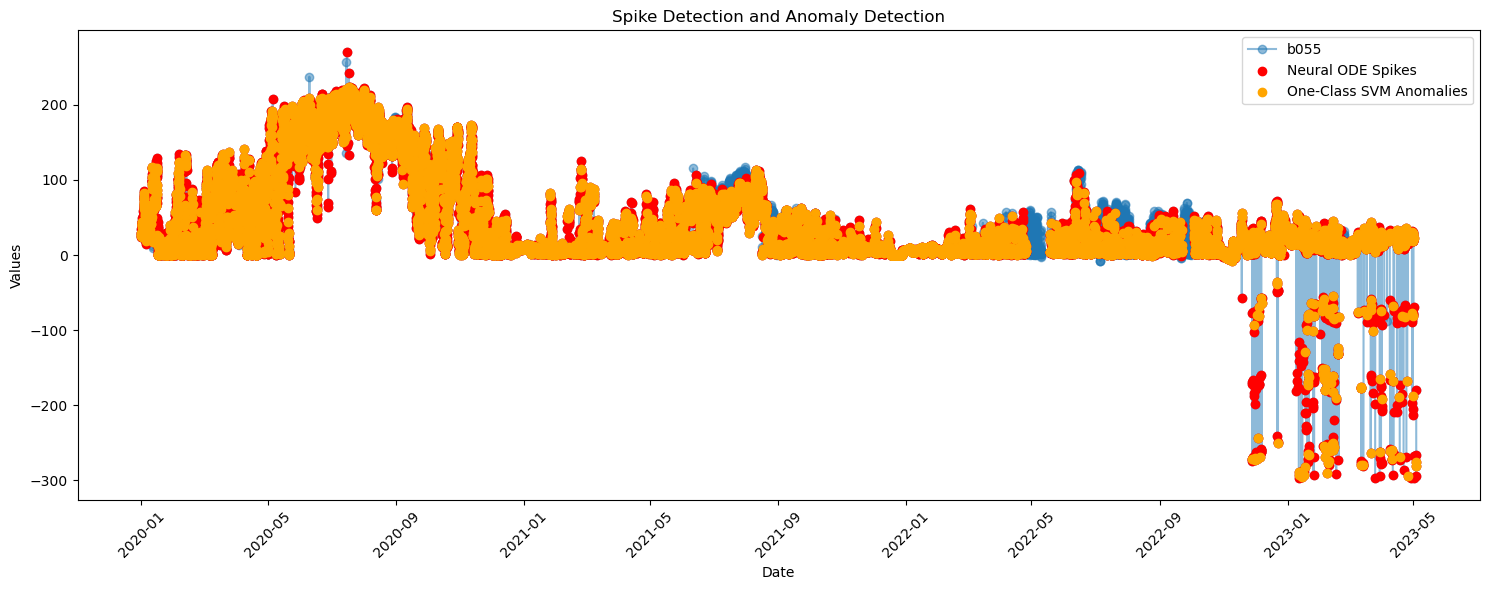

In [66]:
# 데이터 준비
columns = ['b055', 'b103', 'b166', 'b002', 'b084']
threshold = 2

# 스파이크 감지 실행
spikes, data_tensor, valid_indices = detect_spikes_with_periodicity(df, columns, threshold)

# 이상치 감지 실행
anomalies = detect_anomalies(df, columns, data_tensor, valid_indices)

# 결과 시각화
visualize_results(df, 'b055', spikes, anomalies)

In [46]:
import torch
import torch.nn as nn
import torchdiffeq  # Neural ODE library
import matplotlib.pyplot as plt

class ODEFunc(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(ODEFunc, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, input_dim)
    
    def forward(self, t, y):
        y = torch.relu(self.fc1(y))
        return self.fc2(y)

class NeuralODEModel(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = ODEFunc(input_dim, hidden_dim)
    
    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)


# Training loop for Neural ODE
def train_ode_model(model, data, time, epochs=500, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()

        # Initial condition (y0) is the first observation
        y0 = data[0].unsqueeze(0)  # Ensure y0 is of shape [1, num_features]

        # Forward pass through the ODE model
        pred = model(y0, time)

        # Compute loss (reconstruction error)
        huber_loss = nn.HuberLoss()
        loss = huber_loss(pred, data.unsqueeze(0))  # Ensure data has proper shape [1, num_features, num_timesteps]

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

# Anomaly detection: Calculate reconstruction error as anomaly score
def detect_anomalies(model, data, time, threshold=0.1):
    y0 = data[0]
    pred = model(y0, time)
    reconstruction_error = torch.mean((pred - data) ** 2, dim=1)
    anomalies = reconstruction_error > threshold
    return anomalies, reconstruction_error

def plot_predictions(time, true_data, predicted_data):
    num_vars = true_data.shape[1]
    
    plt.figure(figsize=(12, 6 * num_vars))
    for i in range(num_vars):
        plt.subplot(num_vars, 1, i+1)
        plt.plot(time.numpy(), true_data[:, i].numpy(), label='True Data')
        plt.plot(time.numpy(), predicted_data[:, i].detach().numpy(), label='Predicted Data', linestyle='--')
        plt.xlabel('Time (hours)')
        plt.ylabel(f'Variable {i+1}')
        plt.legend()
    plt.tight_layout()
    plt.show()

In [21]:
from fancyimpute import IterativeImputer

# Initialize and train the model
csv_file_path = './CSV data/GT/GT_final_date.csv'  
df = pd.read_csv(csv_file_path)

# Convert 'date' to numerical format (e.g., hours since start)
df['date'] = pd.to_datetime(df['date'])
df['date_numeric'] = (df['date'] - df['date'].min()).dt.total_seconds() / 3600

# Include 'date_numeric' in the imputation process
df2 = df.drop(['date'], axis=1)
data = df2.values

# Initialize MICE imputer
mice_imputer = IterativeImputer()

# Perform imputation
imputed_data = mice_imputer.fit_transform(data)

# Convert imputed data back to DataFrame
imputed_df = pd.DataFrame(imputed_data, columns=df2.columns)
imputed_df['date'] = df['date'] 
imputed_df['date_numeric'] = (imputed_df['date'] - imputed_df['date'].min()).dt.total_seconds() / 3600

In [23]:
# Ensure time steps are unique and sufficiently spaced
time = torch.tensor(imputed_df['date_numeric'].values, dtype=torch.float32)
time_diff = time.diff()

# Adjust time steps if any are zero or too small
min_time_step = 1e-2  # Set a minimum allowed time step
time_diff = torch.where(time_diff == 0, min_time_step, time_diff)  # Replace zero differences

# Recalculate time from the adjusted differences
time_adjusted = torch.cumsum(time_diff, dim=0)
time_adjusted = torch.cat((torch.tensor([time[0]]), time_adjusted))  # Include the initial time

# Normalize time between 0 and 1
time_normalized = (time_adjusted - time_adjusted.min()) / (time_adjusted.max() - time_adjusted.min())

# Convert imputed data to PyTorch tensor
data = torch.tensor(imputed_df.drop(['date', 'date_numeric'], axis=1).values, dtype=torch.float32)

In [24]:
# Initialize and train the model
input_dim = data.shape[1]  # Number of features in the data
hidden_dim = 50  # Hidden dimension size

ode_model = NeuralODEModel(input_dim, hidden_dim)
train_ode_model(ode_model, data, time_normalized)

# Predict and plot
y0 = data[0].unsqueeze(0)  # Initial condition for prediction
predicted = ode_model(y0, time_normalized)

/opt/anaconda3/envs/career/lib/python3.11/site-packages/torch/nn/modules/loss.py:999: UserWarning: Using a target size (torch.Size([1, 29256, 6])) that is different to the input size (torch.Size([29256, 1, 6])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.huber_loss(input, target, reduction=self.reduction, delta=self.delta)


Epoch 0, Loss: 6429071.0
Epoch 10, Loss: 6169923.5
Epoch 20, Loss: 6042227.5
Epoch 30, Loss: 5962905.0
Epoch 40, Loss: 5904445.5
Epoch 50, Loss: 5860411.5
Epoch 60, Loss: 5819851.0
Epoch 70, Loss: 5778532.0
Epoch 80, Loss: 5736408.0
Epoch 90, Loss: 5696644.0
Epoch 100, Loss: 5656487.0
Epoch 110, Loss: 5617336.5
Epoch 120, Loss: 5577563.0
Epoch 130, Loss: 5539727.5
Epoch 140, Loss: 5502061.5
Epoch 150, Loss: 5462732.0
Epoch 160, Loss: 5426233.0
Epoch 170, Loss: 5389188.0
Epoch 180, Loss: 5354967.5
Epoch 190, Loss: 5317069.5
Epoch 200, Loss: 5283030.5
Epoch 210, Loss: 5247810.5
Epoch 220, Loss: 5215267.0
Epoch 230, Loss: 5182472.0
Epoch 240, Loss: 5152455.0
Epoch 250, Loss: 5120677.0
Epoch 260, Loss: 5091159.0
Epoch 270, Loss: 5063383.5
Epoch 280, Loss: 5035992.5
Epoch 290, Loss: 5009796.5
Epoch 300, Loss: 4984998.0
Epoch 310, Loss: 4959976.5
Epoch 320, Loss: 4936718.0
Epoch 330, Loss: 4913600.5
Epoch 340, Loss: 4891809.0
Epoch 350, Loss: 4870829.5
Epoch 360, Loss: 4850446.0
Epoch 370, L

In [27]:
import torch
import torchdiffeq
from nflows import transforms, distributions, flows

class FlowLayer(torch.nn.Module):
    def __init__(self, input_dim):
        super(FlowLayer, self).__init__()
        self.base_dist = distributions.StandardNormal([input_dim])
        self.transform = transforms.CompositeTransform([
            transforms.AffineCoupling(input_dim=input_dim // 2),
            transforms.ActNorm(input_dim),
        ])
        self.flow = flows.Flow(self.transform, self.base_dist)

    def forward(self, x):
        # Forward pass through normalizing flow
        z, log_det = self.flow._transform.forward(x)
        return z, log_det

class NeuralODEModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(NeuralODEModel, self).__init__()
        self.odefunc = torch.nn.Sequential(
            torch.nn.Linear(input_dim, hidden_dim),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_dim, input_dim),
        )

    def forward(self, y0, t):
        return torchdiffeq.odeint(self.odefunc, y0, t)

class CombinedModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(CombinedModel, self).__init__()
        self.flow_layer = FlowLayer(input_dim)
        self.ode_layer = NeuralODEModel(input_dim, hidden_dim)

    def forward(self, x, t):
        # Forward pass through normalizing flow first
        z, log_det = self.flow_layer(x)
        # Then pass through the neural ODE
        z_ode = self.ode_layer(z, t)
        return z_ode, log_det

# Loss function that combines reconstruction and flow log-likelihood
def loss_function(pred, true, log_det, weight=1.0):
    # Reconstruction loss (e.g., MSE)
    reconstruction_loss = torch.nn.functional.mse_loss(pred, true)
    # Flow log-likelihood loss
    flow_loss = -log_det.mean()
    return reconstruction_loss + weight * flow_loss

# Example training loop
def train_combined_model(model, data, time, epochs=100, lr=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        # Initial condition for ODE
        y0 = data[0].unsqueeze(0)
        pred, log_det = model(y0, time)

        # Compute loss
        loss = loss_function(pred, data, log_det)

        # Backpropagation
        loss.backward()
        optimizer.step()

        if epoch % 10 == 0:
            print(f'Epoch {epoch}, Loss: {loss.item()}')

### ID-CNN & LSTM-AE

In [21]:
reconstructed_data.index = reconstructed_data['ds']
reconstructed_data = reconstructed_data.drop(['ds'], axis = 1)

In [23]:
prof1.index = prof1['ds']
prof1 = prof1.drop(['Date/Time', 'ds'], axis = 1)

In [25]:
# Input
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 
num_samples = len(signal_train) 

# 추세와 계절성 데이터 추출 (이전에 설명한 방법 사용)
input_layer = Input(shape=(num_samples, 1))
conv1 = Conv1D(filters=16, kernel_size=5, activation='relu')(input_layer)
maxpool1 = MaxPooling1D(pool_size=2)(conv1)
conv2 = Conv1D(filters=32, kernel_size=5, activation='relu')(maxpool1)
maxpool2 = MaxPooling1D(pool_size=2)(conv2)
flatten = Flatten()(maxpool2)

# 추세 및 계절성 패턴을 추출하는 모델 생성
model = keras.Model(inputs = input_layer, outputs = flatten)
model.compile(optimizer = 'adam', loss = 'mse')

train_data = signal_train.reshape(1, len(signal_train), 1)
model.fit(train_data, train_data, epochs=50, batch_size=16, validation_data=(train_data, train_data))
val_data = signal_valid.reshape(1, num_samples - len(signal_valid), 1)
predictions = model.predict(val_data)

# LSTM Autoencoder 모델 정의
encoding_dim = 64
timesteps = num_samples
features = 1

Epoch 1/50


ValueError: in user code:

    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1377, in train_function  *
        return step_function(self, iterator)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1360, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1349, in run_step  **
        outputs = model.train_step(data)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1127, in train_step
        loss = self.compute_loss(x, y, y_pred, sample_weight)
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/site-packages/keras/src/engine/training.py", line 1185, in compute_loss
        return self.compiled_loss(
    File "/Users/jieun/anaconda3/envs/paper/lib/python3.9/si

In [26]:
num_series = 1
epochs = 10
window_size = 10

# 1D CNN (extract trend & seasonality)
def extract_trend_seasonality(series, window_size):
    model = Sequential([
        Conv1D(filters = 32, kernel_size = window_size, activation = 'relu', input_shape = (None, 1)),
        MaxPooling1D(pool_size = 2),
        LSTM(50, activation = 'relu'),
        Dense(1)
    ])

    model.compile(optimizer = 'adam', loss = 'mse')
    series = np.array(series).reshape((num_series, -1, 1))
    model.fit(series, series, epochs = epochs)

    # 추출된 트렌드 및 시즌얼리 데이터
    trend_seasonality = model.predict(series)
    return trend_seasonality

# LSTM을 통한 훈련
def train_lstm_on_trend_seasonality(trend_seasonality):
    model = Sequential([
        LSTM(50, activation='relu', input_shape = (None, 1), return_sequences = True),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mae')
    trend_seasonality = np.array(trend_seasonality).reshape((num_series, -1, 1))
    model.fit(trend_seasonality, trend_seasonality, epochs = epochs)

    return model

# 트렌드 및 시즌얼리 데이터 추출
trend_seasonality = extract_trend_seasonality(signal_train, window_size)

# LSTM을 통한 훈련
lstm_model = train_lstm_on_trend_seasonality(trend_seasonality)


Epoch 1/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 2/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 3/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 4/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 5/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 6/10
1/1 [==============================] - 9s 9s/step - loss: 0.1426
Epoch 7/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 8/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 9/10
1/1 [==============================] - 8s 8s/step - loss: 0.1426
Epoch 10/10
1/1 [==============================] - 0s 436ms/step
Epoch 1/10
1/1 [==============================] - 1s 607ms/step - loss: 0.0015
Epoch 2/10
1/1 [==============================] - 0s 3ms/step - loss: 6.6912e-06
Epoch 3/10
1/1 [==============================] - 0s 3ms/step - loss: 0.0014
Epoch 4/10
1/1

In [88]:
# 예측 및 시각화
signal_test[np.isnan(signal_test)] = 0
test_series = signal_test
test_series = np.array(test_series).reshape((-1, 1))

predicted_trend_seasonality = lstm_model.predict(test_series.reshape((1, -1, 1)))

1/1 [==============================] - 1s 662ms/step


In [84]:
predicted_trend_seasonality

array([[0.00475079]], dtype=float32)

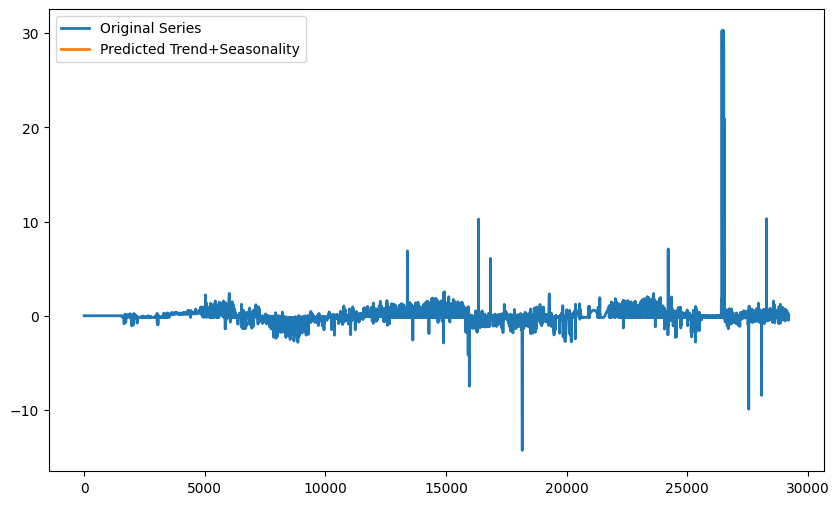

In [83]:
plt.figure(figsize=(10, 6))
plt.plot(test_series[:, :], label='Original Series', linewidth=2)
plt.plot(predicted_trend_seasonality[:, :], label='Predicted Trend+Seasonality', linewidth=2)
plt.legend()
plt.show()

In [61]:
predicted_trend_seasonality = lstm_model.predict(test_series)

1/1 [==============================] - 1s 699ms/step


### LSTM-AE with reconstructed_data as normal

In [58]:
reconstructed_data.index = pd.to_datetime(reconstructed_data['ds'])
reconstructed_data = reconstructed_data.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/1548268338.py:2: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [59]:
# orignal data
prof1.index = pd.to_datetime(prof1['ds'])
prof1 = prof1.fillna(method = "ffill")

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/2715252278.py:3: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [60]:
### split data
signal_train = reconstructed_data['2020-01-01':'2023-01-31']['y'].values 
signal_valid = reconstructed_data['2023-02-01':'2023-05-01']['y'].values 
signal_test = prof1['2020-01-01':'2023-05-01']['y'].values 

# set window length
window_length = 12 * 2

train_windows = []

for window_start in range(0, len(signal_train) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_train[window_range])
    train_windows.append(window)
    
# shape of training set
x_train = np.array(train_windows)
x_train.shape

valid_windows = []
for window_start in range(0, len(signal_valid) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_valid[window_range])
    valid_windows.append(window)
    
# shape of validation set
x_valid = np.array(valid_windows)
x_valid.shape

test_windows = []

for window_start in range(0, len(signal_test) - window_length + 1):
    window_end = window_start + window_length
    window_range = range(window_start, window_end)
    window = list(signal_test[window_range])
    test_windows.append(window)

In [79]:
### LSTM Auto-Encoder Model
# optimizer list: adam, adamW, adadelta, adagrad, adamax, nadam

input_length = window_length
input_dim = 1 # number of variable
hidden_dim = 5
batch_size = 64
epochs = 100
opt = keras.optimizers.Adam(learning_rate=0.0005)

def model():
    m = Sequential()
    m.add(LSTM(units=4 * hidden_dim, activation='relu', input_shape=(input_length, input_dim), return_sequences=True))
    m.add(Dropout(rate=0.3))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.1))
    m.add(LSTM(units=2 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(LSTM(units=4 * hidden_dim, activation='relu', return_sequences=True))
    m.add(Dropout(rate=0.2))
    m.add(Dense(1))
    return m

# https://gooopy.tistory.com/90
m = model()
m.compile(loss='mse', optimizer=opt) # adam to rmsprop
m.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 24, 20)            1760      
                                                                 
 dropout_6 (Dropout)         (None, 24, 20)            0         
                                                                 
 lstm_7 (LSTM)               (None, 24, 10)            1240      
                                                                 
 dropout_7 (Dropout)         (None, 24, 10)            0         
                                                                 
 lstm_8 (LSTM)               (None, 24, 5)             320       
                                                                 
 dropout_8 (Dropout)         (None, 24, 5)             0         
                                                                 
 lstm_9 (LSTM)               (None, 24, 5)            

In [80]:
checkpointer = ModelCheckpoint(filepath = "lstm.autoencoder.weights.best.hdf5", verbose = 1, save_best_only = True)
earlystopper = EarlyStopping(monitor = 'val_loss', patience = 10, verbose = 0)
tbCallBack = TensorBoard(log_dir = './lstm.autoencoder.tb.graph', histogram_freq = 0, write_graph = True, write_images = True)

In [81]:
history = m.fit(x_train, x_train, batch_size = batch_size, epochs = epochs, validation_data = (x_valid, x_valid), 
                callbacks = [checkpointer, earlystopper, tbCallBack], verbose = 0).history


Epoch 1: val_loss improved from inf to 0.00350, saving model to lstm.autoencoder.weights.best.hdf5

Epoch 2: val_loss did not improve from 0.00350

Epoch 3: val_loss did not improve from 0.00350

Epoch 4: val_loss did not improve from 0.00350

Epoch 5: val_loss did not improve from 0.00350

Epoch 6: val_loss did not improve from 0.00350

Epoch 7: val_loss did not improve from 0.00350

Epoch 8: val_loss did not improve from 0.00350

Epoch 9: val_loss did not improve from 0.00350

Epoch 10: val_loss did not improve from 0.00350

Epoch 11: val_loss did not improve from 0.00350


In [82]:
pred_x_valid = m.predict(x_valid)

67/67 [==============================] - 1s 5ms/step


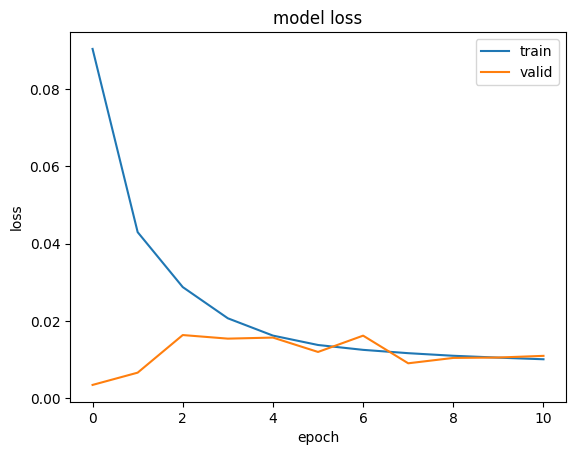

In [83]:
# summarize history for loss
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='best')
plt.show()

In [84]:
x_test = np.array(test_windows)
pred_x_test = m.predict(x_test)

913/913 [==============================] - 5s 5ms/step


In [85]:
# calculate error score
all_errors_valid = pd.Series(np.squeeze((x_valid.shape[:-1]) - pred_x_valid.reshape(pred_x_valid.shape[:-1])[:,:]).flatten())
all_errors_test = pd.Series(np.squeeze((x_test.shape[:-1]) - pred_x_test.reshape(pred_x_test.shape[:-1])[:,:]).flatten())

In [86]:
# calculate error score (window)
def sum_abs_errors_window(errors_in_window):
    return np.sum(np.abs(errors_in_window))

errors_test_per_window = np.squeeze(x_test.shape[:-1] -  pred_x_test.reshape(pred_x_test.shape[:-1])[:,:])
sum_abs_errors_window_0 = np.sum(np.abs(errors_test_per_window[0]))
sum_abs_errors_per_window = pd.Series([sum_abs_errors_window(errors_in_window) for errors_in_window in errors_test_per_window])

In [93]:
# Top anomalous windows ranked and get index
pred_outlier_indices = sum_abs_errors_per_window.nlargest(10).index.values

In [94]:
intervel_length = 1

In [95]:
def highlightComaprison(series, index, colorSTR):
    # Create a mask to identify where the Series values equal 4
    for i in range(len(index)):
        val = series[index[i]]
        mask = ((series) == val) 
        
        # Find the start and end indices of each continuous section where the value equals 4
        section_start = mask & ~mask.shift(fill_value=False)
        section_end = mask & ~mask.shift(-1, fill_value=False)
        
        for start, end in zip(section_start[section_start].index, section_end[section_end].index):
            plt.axvspan(start, end, color=colorSTR, alpha = 0.8)

In [96]:
test = pd.Series(signal_test)
test.index = prof1['2020-01-01':'2023-05-01'].index

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_55753/4180722373.py:4: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



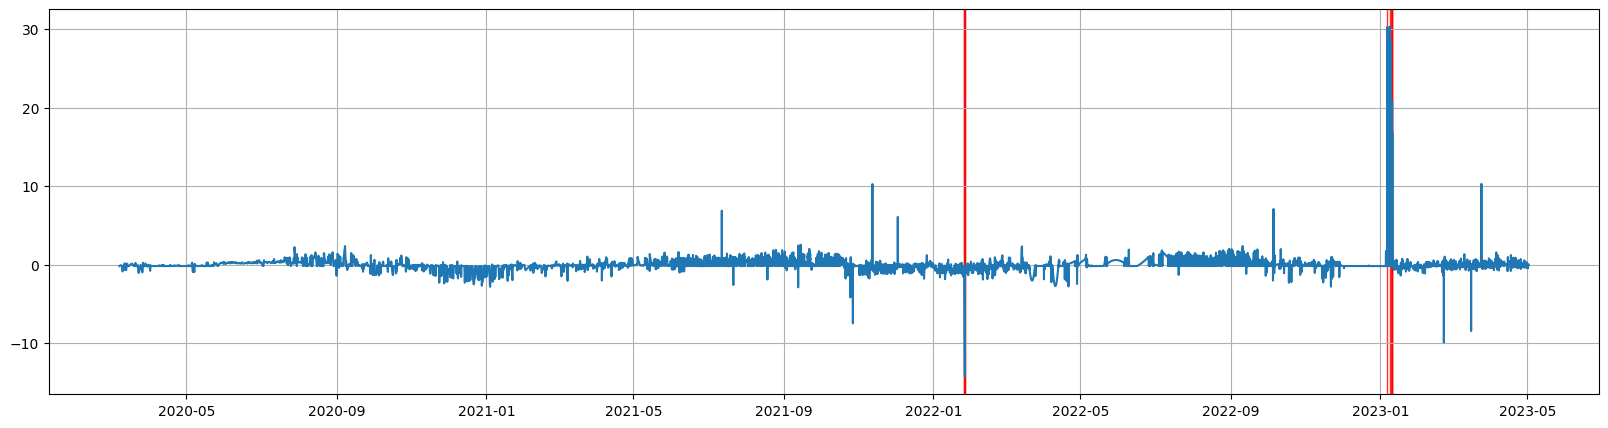

In [97]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(prof1['2020-01-01':'2023-05-01'].index, test)
highlightComaprison(test, pred_outlier_indices, 'red')
plt.grid(True);

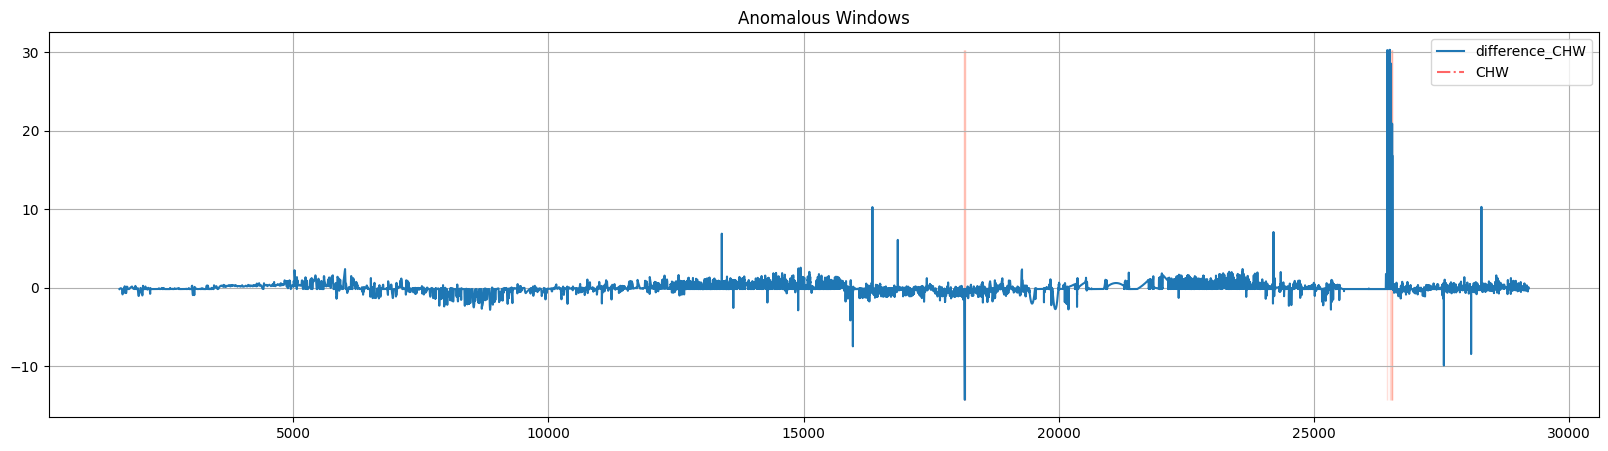

In [98]:
### Visualize anomaly point with test data

plt.figure(figsize = (20, 5))
plt.plot(signal_test)
plt.axhline(y=signal_test.mean(), color='r', linestyle='-.', alpha=0.6) # the  horizontal line for mean
plt.axhline(y=signal_test.mean() + signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean + std_dev
plt.axhline(y=signal_test.mean() + 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean + 2 * std_dev
plt.axhline(y=signal_test.mean() - 2 * signal_test.std(), color='k', linestyle=':', alpha=0.4) # mean - 2 * std_dev
plt.axhline(y=signal_test.mean() - signal_test.std(), color='k', linestyle='--', alpha=0.4) # mean - std_dev
for w_index in pred_outlier_indices:
    plt.fill_betweenx((np.nanmin(signal_test), np.nanmax(signal_test)), w_index, w_index + intervel_length - 1, alpha=0.2, color='tomato')
plt.title('Anomalous Windows')
plt.legend(["difference_CHW", "CHW"])
plt.grid(True);

In [56]:
### Outlier detection (contain None for spike)

data1 = scaled_df[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]
data1[data1 < -0.1] = None
data1[data1 > 0.1] = None
data1 = data1.fillna(method = "ffill")
data1 = data1.dropna()

# Numerical dataframe
from sklearn.cluster import DBSCAN
model = DBSCAN(eps = 0.001, min_samples = 10).fit(data1)

/var/folders/gc/ccxrs945073cqwbghj93h9wr0000gn/T/ipykernel_62669/3009463891.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data1 = data1.fillna(method = "ffill")


In [35]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2'],
      dtype='object')

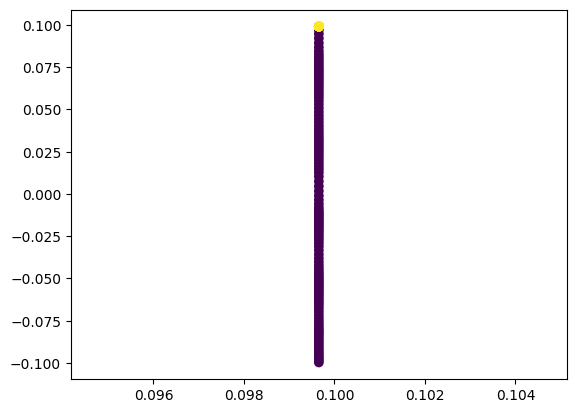

In [38]:
colors = model.labels_
plt.scatter(data1["b084_raw_group2"], data1["b081_raw_group2"], c = colors)

In [39]:
data1[model.labels_ == -1]

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-11-20 19:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.099678
2022-11-20 20:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.098495
2022-11-20 21:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.097326
2022-11-20 22:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.096099
2022-11-20 23:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,-0.094775
...,...,...,...,...,...,...
2022-11-25 13:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.086765
2022-11-25 14:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.089293
2022-11-25 15:00:00,0.099877,0.099437,0.099842,0.099827,0.099655,0.092072


In [40]:
# GMM 모델 생성
n_clusters = 10  # 클러스터 수를 설정
covariance_type = 'spherical'  # 또는 다른 유형 선택 가능

gmm = GaussianMixture(n_components = n_clusters, covariance_type = covariance_type)
gmm.fit(data1)

# 클러스터 할당
cluster_labels = gmm.predict(data1)

# 결과를 데이터프레임에 추가
data1['Cluster_Label'] = cluster_labels

In [41]:
# Isolation Forest 모델 생성
isolation_forest = IsolationForest(contamination=0.05)  # contamination은 이상치 비율을 나타냅니다

# 모델 훈련
isolation_forest.fit(data1)

# 이상치 여부를 예측 (-1은 이상치, 1은 정상치)
outlier_labels = isolation_forest.predict(data1)

# 결과를 데이터프레임에 추가
data1['Outlier_Label'] = outlier_labels

In [42]:
data1.columns

Index(['b055_raw_group2', 'b103_raw_group2', 'b166_raw_group2',
       'b002_raw_group2', 'b084_raw_group2', 'b081_raw_group2',
       'Cluster_Label', 'Outlier_Label'],
      dtype='object')

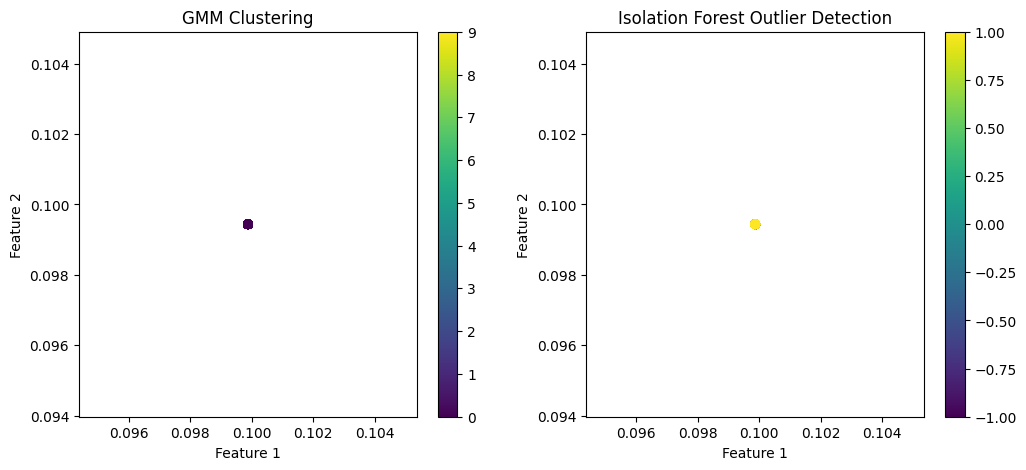

In [44]:
# 클러스터링 결과 및 이상치 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 클러스터링 결과 시각화
scatter1 = ax1.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=cluster_labels, cmap='viridis')
ax1.set_title("GMM Clustering")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
fig.colorbar(scatter1, ax=ax1)

# 이상치 탐지 결과 시각화
scatter2 = ax2.scatter(data1['b055_raw_group2'], data1['b103_raw_group2'], c=outlier_labels, cmap='viridis')
ax2.set_title("Isolation Forest Outlier Detection")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
fig.colorbar(scatter2, ax=ax2)

plt.show()

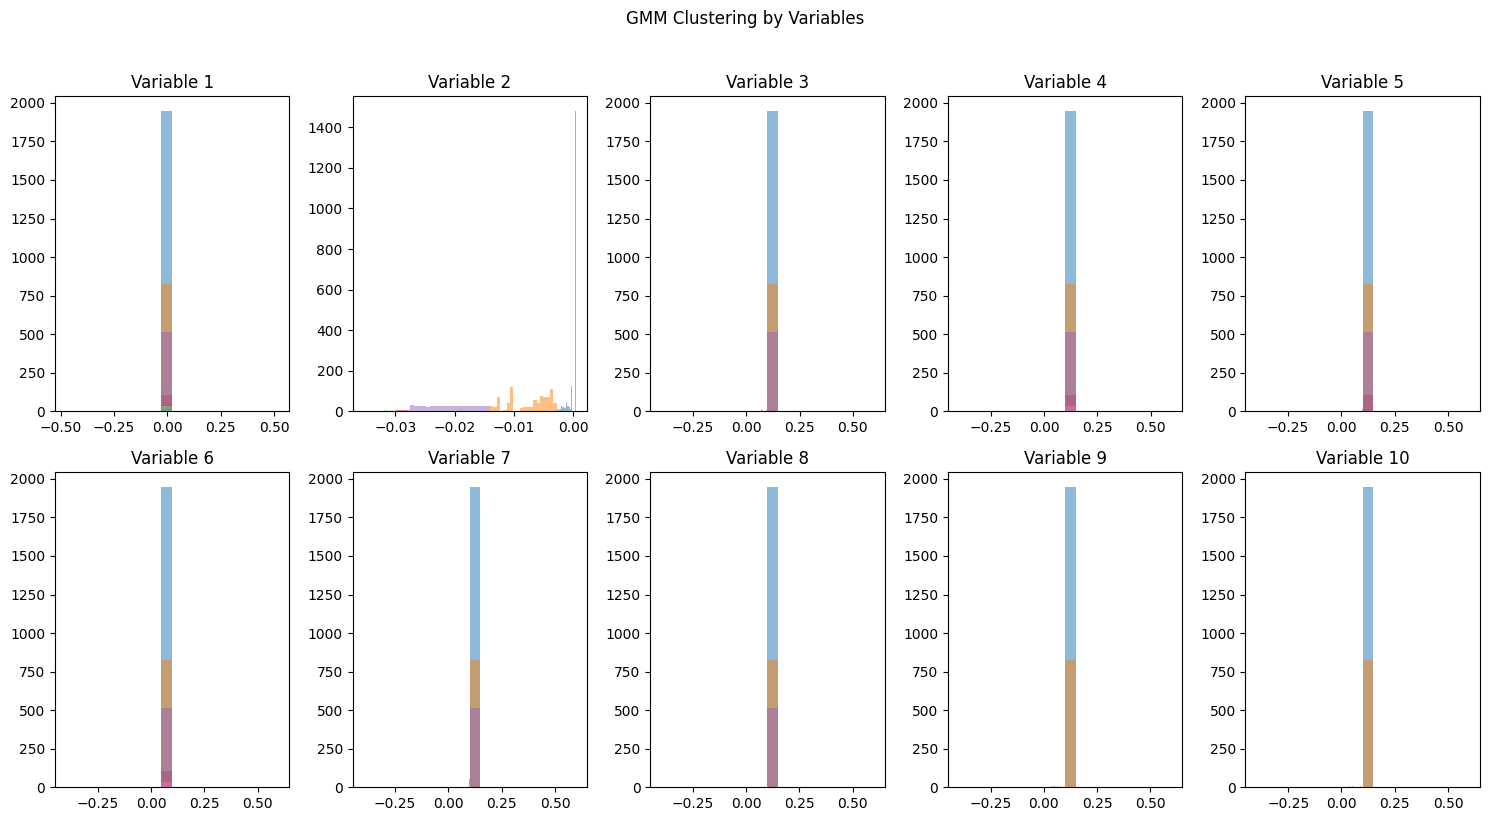

In [103]:
# 클러스터링 결과 시각화
plt.figure(figsize=(15, 8))
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    for i in range(10):  # 10개 변수
        plt.subplot(2, 5, i + 1)
        plt.hist(cluster_data.iloc[:, i], bins = 20, alpha = 0.5, label = f'Cluster {cluster_label + 1}')
        plt.title(f'Variable {i + 1}')
    
plt.suptitle("GMM Clustering by Variables", y = 1.02)
plt.tight_layout()
plt.show()

In [105]:
cluster_data

,b181_raw_group1,b146_raw_group1,b153_raw_group1,b147_raw_group1,b165_raw_group1,b167_raw_group1,b195_raw_group1,b790_raw_group1,b116_raw_group1,b064_raw_group1,Cluster_Label,Outlier_Label
Date/Time,,,,,,,,,,,,
2022-10-11 22:00:00,0.021912,-0.002759,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-11 23:00:00,0.021912,-0.002746,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 00:00:00,0.021912,-0.002732,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 01:00:00,0.021912,-0.002716,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-10-12 02:00:00,0.021912,-0.002699,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31 18:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 19:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1
2022-12-31 20:00:00,0.021912,0.000575,0.099478,0.099155,0.099923,0.099232,0.099987,0.09958,0.099452,0.09975,0,1


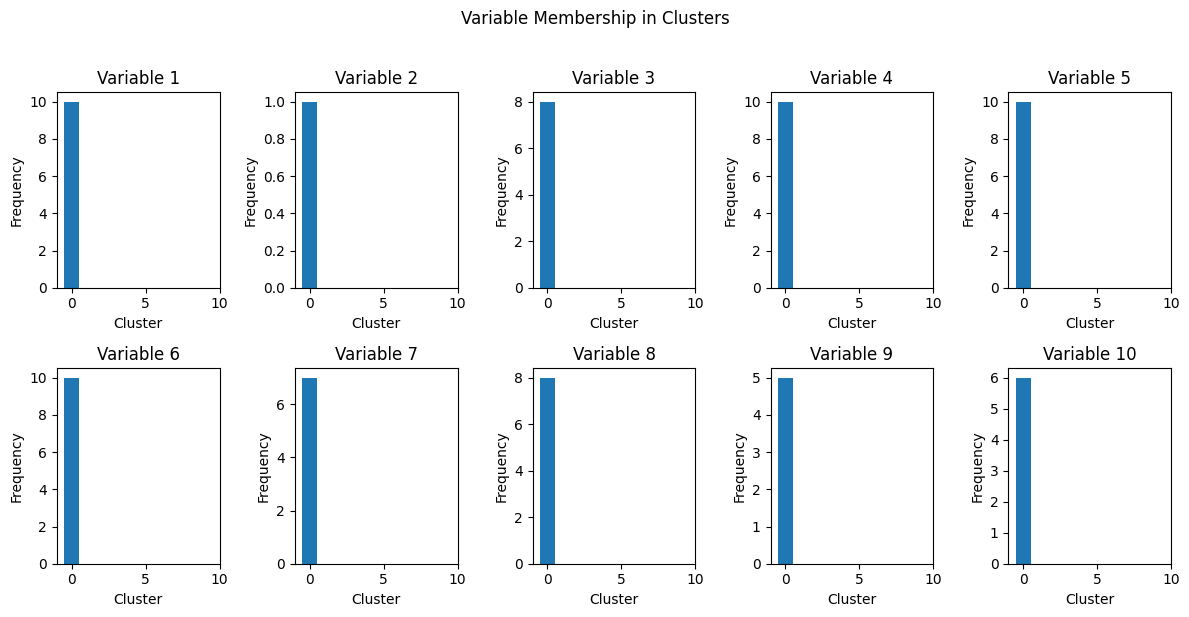

In [107]:
import numpy as np

# 각 변수의 클러스터 소속 확인
variable_cluster_labels = np.zeros((10, n_clusters))  # 변수의 개수 x 클러스터 수
for cluster_label in range(n_clusters):
    cluster_data = data1[cluster_labels == cluster_label]
    cluster_data = cluster_data.drop(['Cluster_Label', "Outlier_Label"], axis = 1)
    variable_cluster_labels[:, cluster_label] = np.mean(cluster_data, axis=0)


# 변수별 클러스터 소속 시각화
plt.figure(figsize=(12, 6))
for i in range(10):  # 10개 변수
    plt.subplot(2, 5, i + 1)
    counts, bins, _ = plt.hist(variable_cluster_labels[i], bins=range(n_clusters + 1), align='left')
    plt.title(f'Variable {i + 1}')
    plt.xlabel('Cluster')
    plt.ylabel('Frequency')
    
plt.suptitle("Variable Membership in Clusters", y=1.02)
plt.tight_layout()
plt.show()


### Generate NAN and Impute GAN (pilot)

In [79]:
data1 = data1.reset_index()
# data1 = data1.drop(['Index'], axis = 1)

In [ ]:
# 결측값 생성

num_points = len(data1)
num_variables = 6
missing_rate = 0.2
for column in df.columns:
    num_missing = int(num_points * missing_rate)
    missing_indices = np.random.choice(num_points, num_missing, replace=False)
    data1.loc[missing_indices, column] = np.nan

In [87]:
data1.index = data1["Date/Time"]
data1 = data1.drop(['Date/Time', "index"], axis = 1)

# Extract data with pt
filtered_columns = [col for col in data1.columns if "raw" in col]

# 선택한 변수를 새로운 데이터 프레임으로 추출
data1 = data1[filtered_columns]["2022-04-01 00:00:00": "2022-12-31 22:00:00"]

In [111]:
from tensorflow import keras
import torch
import torch.nn as nn
import torch.optim as optim

In [88]:
data1.head()

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
Date/Time,,,,,,
2022-04-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-01 01:00:00,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2022-04-01 02:00:00,0.0,0.000058,0.000281,NaN,NaN,NaN
2022-04-01 03:00:00,0.0,0.000035,0.000268,0.000308,NaN,NaN
2022-04-01 04:00:00,0.0,NaN,NaN,0.000298,NaN,NaN


In [91]:
data1 = data1.reset_index()
data1 = data1.drop(['Date/Time'], axis = 1)

In [93]:
data1

,b055_raw_group2,b103_raw_group2,b166_raw_group2,b002_raw_group2,b084_raw_group2,b081_raw_group2
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,0.000047,0.000284,0.000306,0.000469,NaN
2,0.0,0.000058,0.000281,NaN,NaN,NaN
3,0.0,0.000035,0.000268,0.000308,NaN,NaN
4,0.0,NaN,NaN,0.000298,NaN,NaN
...,...,...,...,...,...,...
6594,0.0,0.000035,0.000287,NaN,0.000000,0.000426
6595,0.0,NaN,NaN,0.000286,NaN,NaN
6596,0.0,NaN,0.000265,0.000288,0.000012,0.000416
6597,NaN,NaN,0.000216,NaN,0.000000,0.000435


In [116]:
# 데이터프레임을 PyTorch 텐서로 변환
real_data = torch.FloatTensor(data1.dropna().values)

In [122]:
# Generator 모델 정의
class Generator(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(Generator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, output_dim),
            nn.Tanh()
        )

    def forward(self, x):
        return self.fc(x)

# Discriminator 모델 정의
class Discriminator(nn.Module):
    def __init__(self, input_dim):
        super(Discriminator, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.fc(x)

In [128]:
# Generator와 Discriminator 모델 초기화
input_dim = 32
output_dim = num_variables
generator = Generator(input_dim, output_dim)
discriminator = Discriminator(output_dim)

# 손실 함수 및 옵티마이저 정의
criterion = nn.BCELoss()
optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)

In [134]:
# GAN 모델 훈련
num_epochs = 100
batch_size = 32

for epoch in range(num_epochs):
    num_batches = real_data.shape[0] // batch_size
    for _ in range(num_batches):
        noise = torch.randn(batch_size, input_dim)
        generated_data = generator(noise)
        real_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        fake_labels = torch.zeros((batch_size, 1), dtype=torch.float32)

        # Discriminator 훈련
        optimizer_d.zero_grad()
        real_output = discriminator(real_data[:batch_size])
        fake_output = discriminator(generated_data)
        discriminator_loss_real = criterion(real_output, real_labels)
        discriminator_loss_fake = criterion(fake_output, fake_labels)
        discriminator_loss = discriminator_loss_real + discriminator_loss_fake
        discriminator_loss.backward(retain_graph=True)
        optimizer_d.step()

        # Generator를 통한 GAN 훈련
        optimizer_g.zero_grad()
        gan_labels = torch.ones((batch_size, 1), dtype=torch.float32)
        gan_output = discriminator(generated_data)
        gan_loss = criterion(gan_output, gan_labels)
        gan_loss.backward()
        optimizer_g.step()

    print(f'Epoch {epoch}, D Loss: {discriminator_loss.item()}, G Loss: {gan_loss.item()}')


Epoch 0, D Loss: 1.3854780197143555, G Loss: 0.6327202320098877
Epoch 1, D Loss: 1.3908488750457764, G Loss: 0.6290866136550903
Epoch 2, D Loss: 1.3863091468811035, G Loss: 0.6368914246559143
Epoch 3, D Loss: 1.3897672891616821, G Loss: 0.6354539394378662
Epoch 4, D Loss: 1.3817918300628662, G Loss: 0.6448863744735718
Epoch 5, D Loss: 1.3989853858947754, G Loss: 0.6333292722702026
Epoch 6, D Loss: 1.372666358947754, G Loss: 0.6603043675422668
Epoch 7, D Loss: 1.3731648921966553, G Loss: 0.6610397100448608
Epoch 8, D Loss: 1.3767998218536377, G Loss: 0.6590506434440613
Epoch 9, D Loss: 1.3822531700134277, G Loss: 0.6567761898040771
Epoch 10, D Loss: 1.379887342453003, G Loss: 0.6593412160873413
Epoch 11, D Loss: 1.3736572265625, G Loss: 0.6676796078681946
Epoch 12, D Loss: 1.3731087446212769, G Loss: 0.6703320145606995
Epoch 13, D Loss: 1.3778290748596191, G Loss: 0.6668186783790588
Epoch 14, D Loss: 1.3695826530456543, G Loss: 0.6758610606193542
Epoch 15, D Loss: 1.371976613998413, G L

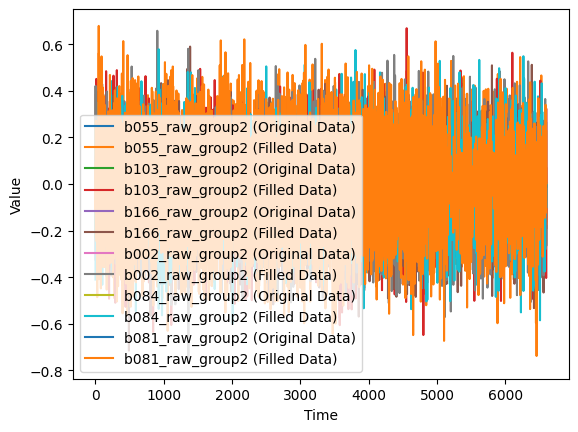

In [136]:
# 결측값을 GAN을 사용하여 채우기
missing_data = data1.copy()
for column in missing_data.columns:
    missing_indices = missing_data[column].isna()
    num_missing = missing_indices.sum()
    noise = torch.randn(num_missing, input_dim)
    generated_values = generator(noise).detach().numpy()
    missing_data.loc[missing_indices, column] = generated_values.flatten()[:num_missing]

# 결과를 시각화
for column in data1.columns:
    plt.plot(data1[column], label=f'{column} (Original Data)')
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

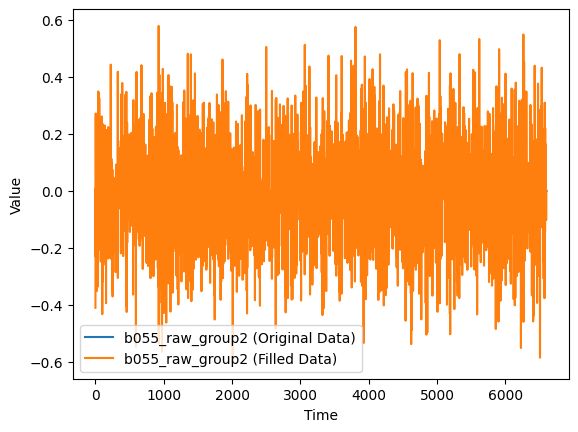

In [148]:
# 결과를 시각화

plt.plot(data1["b084_raw_group2"], label=f'{column} (Original Data)')
plt.plot(missing_data["b084_raw_group2"], label=f'{column} (Filled Data)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

ValueError: x and y must be the same size

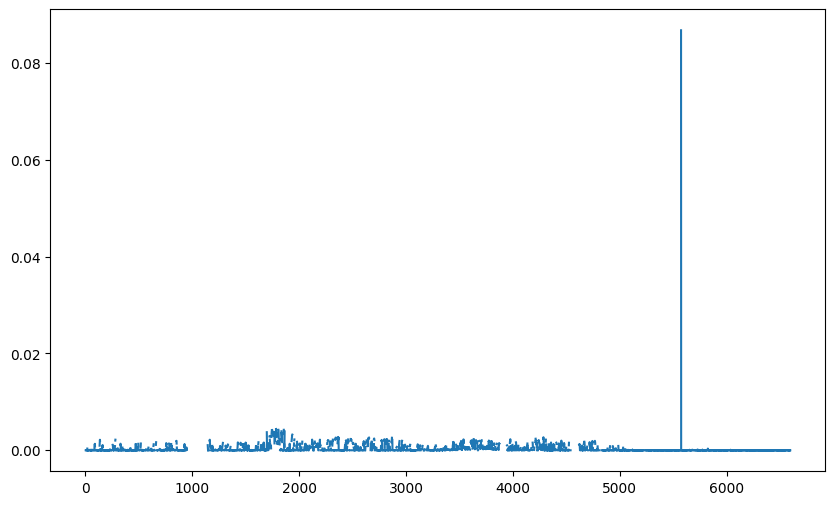

In [141]:
# 결과를 시각화
for column in data1.columns:
    plt.figure(figsize=(10, 6))
    plt.plot(data1[column], label=f'{column} (Original Data)')
    
    # 결측값인 지점에 동그라미 표시
    missing_indices = data1[column].isna()
    plt.scatter(missing_indices.index, data1[column][missing_indices], c='r', marker='o', label='Missing Data')
    
    plt.plot(missing_data[column], label=f'{column} (Filled Data)')
    
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    plt.show()